# 06 · NLP - do the words of a tender help us spot single-bid tenders?

In S5 the number clues (department rate, value, bid window ...) could not beat random checking on validation, because the pattern changed after Sep 2022 (drift).

In this section we read the words of each tender (title + work description) and ask 3 questions:
1. Do the words tell us something new (new clues, the reason behind the December drop)?
2. Do the words help a model find single-bid tenders better than the S5 methods?
3. Are any gains real, or only luck or a timing mistake?

Test (Jan-May 2023) stays locked. We only look at train and validation answers.

| Part | Steps | Simple meaning |
|---|---|---|
| A | 1-4 | Get to know the text |
| B | 5-9 | Make new text clues and look for the reason behind the drift |
| C | 10-18 | Prediction with text, and fair checks |
| D | 19-23 | Results table, auditor view, saves, extra checks, summary |

## Step 1 · Load the data and make one text column

In [1]:
# pandas = tables, numpy = maths helpers
import pandas as pd
import numpy as np

In [2]:
# matplotlib = charts, os = folders
import matplotlib.pyplot as plt
import os

In [3]:
# Let Python look one folder up, where tenderlens_style.py lives
import sys
sys.path.append("..")

In [4]:
# My colours and chart helpers with the short name ts
import tenderlens_style as ts

In [5]:
# Logistic Regression = a simple weighted score (our main model from S5)
from sklearn.linear_model import LogisticRegression

In [6]:
# Scaler = puts all clues on the same size scale
from sklearn.preprocessing import StandardScaler

In [7]:
# Two scores: PR-AUC and ROC-AUC (same as S5)
from sklearn.metrics import average_precision_score
from sklearn.metrics import roc_auc_score

In [8]:
# CountVectorizer = counts words; TfidfVectorizer = turns words into numbers (more on this later)
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.feature_extraction.text import TfidfVectorizer

In [9]:
# cosine_similarity = how alike two texts are (0 = nothing in common, 1 = same words)
from sklearn.metrics.pairwise import cosine_similarity

In [10]:
# hstack = glue two number tables side by side; csr_matrix = a table that stores mostly zeros cheaply
from scipy.sparse import hstack
from scipy.sparse import csr_matrix

In [11]:
# The clue table from S5 (one row = one labelled tender, 34 clues)
lab = pd.read_csv("../data/processed/features_split_v2.csv", parse_dates=["published_date"])
lab.shape

(6790, 46)

In [12]:
# The full clean table from S2 (all 39,411 tenders), needed for re-tender checks
df = pd.read_csv("../data/interim/tenders_clean.csv", parse_dates=["published_date", "bid_opening_date"])
df.shape

(39411, 39)

In [13]:
# Two extra columns from the clean table:
# title_key = cleaned title (to find copies), bid_opening_date = day the bids were opened
lab = lab.merge(df[["tender_id", "title_key", "bid_opening_date"]], on="tender_id", how="left")
lab.shape

(6790, 48)

In [14]:
# How often is the work description just the same as the title?
same_desc = lab["title"] == lab["work_description"]
print("Description same as title:", round(same_desc.mean() * 100, 1), "%")

Description same as title: 60.9 %


In [15]:
# One text column: the title, plus the description only when it adds something new
lab["text"] = np.where(same_desc, lab["title"], lab["title"] + " " + lab["work_description"])

In [16]:
# Look at 3 example texts
for t in lab["text"].head(3):
    print("-", t)

- MLCSNA/Sonitpur/09 MLCSNA/Sonitpur/09 Construction of RCC Bridge No.1/1 over river Burigang in Pub Moral gaon to Nalbari Road Construction of RCC Bridge No.1/2 over river Burigang in Moral gaon Bahbari pam Link Road
- SOPD_GL_33 Improvement Rajmita to Kathuri Road (from Ch 0.00 to 1800.00m) under SOPD for 2018-19 (PMGSY, Package No ASD-07-24)
- CONSTRUCTION OF DRAIN AT WEST MILAN NAGAR AREA, DIBRUGARH UNDER CIDF. CONSTRUCTION OF DRAIN AT WEST MILAN NAGAR AREA, DIBRUGARH UNDER CIDF


In [17]:
# Train and validation together (test stays locked), then the two parts
tv = lab[lab["split"] != "test"]
train = lab[lab["split"] == "train"]
val = lab[lab["split"] == "val"]
print("Train:", len(train), " Validation:", len(val))

Train: 2753  Validation: 2270


In [18]:
# The real answers for train and validation
y_tr = train["single_bid"]
y_va = val["single_bid"]

In [19]:
# The 7 base clues from S4
base = ["dept_rate", "log_value", "value_missing", "bid_window_days",
        "months_to_fy_end", "same_day_lot", "retender_60d"]

In [20]:
# The 27 extra clues from S5
new = ["cat_Goods", "cat_Services", "cat_Works",
       "form_Item Rate", "form_Item Wise", "form_Lump-sum", "form_Other",
       "form_Percentage", "form_Supply", "form_Turn-key", "form_Works",
       "not_open", "prod_rate", "times_before",
       "kw_maintenance", "kw_printing", "kw_supply", "kw_building",
       "kw_construction", "kw_road", "kw_repair", "kw_renovation",
       "emd_ratio", "log_fee", "work_period_days", "weekday", "pub_hour"]

In [21]:
# All 34 clues
full = base + new
len(full)

34

## Step 2 · Text check: empty, short or long descriptions

In [22]:
# Any empty titles or descriptions? (0 = none)
print("Empty titles:", lab["title"].isna().sum(), "| Empty descriptions:", lab["work_description"].isna().sum())

Empty titles: 0 | Empty descriptions: 0


In [23]:
# Longest description (the portal cuts text at 250 letters, so details are not here)
lab["work_description"].str.len().max()

250

In [24]:
# Number of words in each text
words_count = tv["text"].str.split().str.len()
words_count.describe().round(1)

count    5023.0
mean       26.3
std        12.6
min         2.0
25%        16.5
50%        25.0
75%        35.0
max        89.0
Name: text, dtype: float64

In [25]:
# Put each text into a length group: short (up to 10 words), medium (11-20), long (21+)
length_group = pd.cut(words_count, bins=[0, 10, 20, 1000], labels=["Short (1-10 words)", "Medium (11-20)", "Long (21+)"])

In [26]:
# Single-bid rate (%) and number of tenders in each length group, train vs validation
length_table = pd.DataFrame()
length_table["train n"] = length_group[tv["split"] == "train"].value_counts()
length_table["train %"] = tv[tv["split"] == "train"].groupby(length_group, observed=True)["single_bid"].mean() * 100
length_table["val n"] = length_group[tv["split"] == "val"].value_counts()
length_table["val %"] = tv[tv["split"] == "val"].groupby(length_group, observed=True)["single_bid"].mean() * 100
length_table = length_table.loc[["Short (1-10 words)", "Medium (11-20)", "Long (21+)"]]   # short to long
length_table.round(1)

,train n,train %,val n,val %
text,,,,
Short (1-10 words),310,33.9,126,24.6
Medium (11-20),968,37.2,423,32.4
Long (21+),1475,35.8,1721,26.8


In [27]:
# Does a description that adds new words matter? (same as title vs adds more)
same_tv = same_desc[tv.index]
print("Train | same:", round(train.loc[same_tv[train.index], "single_bid"].mean() * 100, 1),
      "% | adds more:", round(train.loc[~same_tv[train.index], "single_bid"].mean() * 100, 1), "%")
print("Val   | same:", round(val.loc[same_tv[val.index], "single_bid"].mean() * 100, 1),
      "% | adds more:", round(val.loc[~same_tv[val.index], "single_bid"].mean() * 100, 1), "%")

Train | same: 37.4 % | adds more: 33.9 %
Val   | same: 26.4 % | adds more: 30.3 %


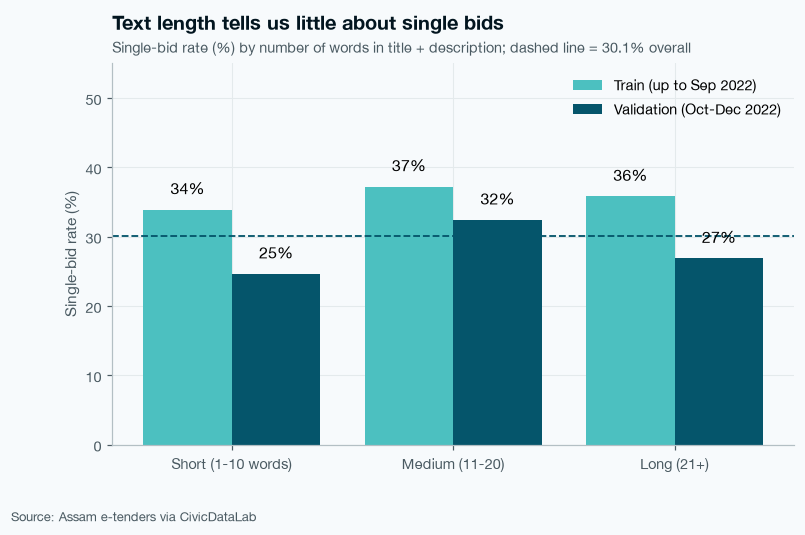

In [28]:
# Chart S6a: single-bid rate by text length, train vs validation
fig, ax = plt.subplots(figsize=(8, 4.5))
pos = np.arange(len(length_table))
b1 = ax.bar(pos - 0.2, length_table["train %"], width=0.4, color=ts.BLUES[2], label="Train (up to Sep 2022)")
b2 = ax.bar(pos + 0.2, length_table["val %"], width=0.4, color=ts.BLUES[4], label="Validation (Oct-Dec 2022)")

# % labels on top of the bars
ax.bar_label(b1, fmt="%.0f%%", padding=8)
ax.bar_label(b2, fmt="%.0f%%", padding=8)

# Dashed benchmark line at the overall 30.1%
ax.axhline(30.1, color=ts.THIRD, linestyle="--", linewidth=1.2)

# Group names, y-axis name, room at the top, legend
ax.set_xticks(pos, length_table.index)
ax.set_ylabel("Single-bid rate (%)")
ax.set_ylim(0, 55)
ax.legend(loc="upper right")

# Title = the finding, subtitle = what is measured, then the source line
ts.title(ax, "Text length tells us little about single bids",
         subtitle="Single-bid rate (%) by number of words in title + description; dashed line = 30.1% overall")
ts.source(fig)

In [29]:
# Make sure the folder exists, then save the chart
os.makedirs("../reports/figures", exist_ok=True)
ts.save_fig(fig, "../reports/figures/S6a_text_length.png")

### Insight · Text check (Steps 1 and 2)

- I joined the title and the work description of each tender into one text.
- In 60.9% of tenders the description is just a copy of the title. So most descriptions add nothing new.
- No title or description was empty. But the portal stops every description at 250 letters, so the real details of the work are not in our data.
- A normal tender text is about 25 words long.
- Short, medium and long texts all had about the same single-bid rate in train (34% to 37%). In validation all of them went down (25% to 32%), the same drop we saw in S5.
- So the length of the text does not help us find single-bid tenders.

## Step 3 · Copies: the same work posted many times

Two kinds of copies:
- Copies inside validation: the same department posts the same title many times (lots of one big work).
- Copies of training tenders: a validation tender that looks almost the same as an older training tender.

In [30]:
# Copies inside validation: how many tenders share the same department + cleaned title
copies = val.groupby(["dept_main", "title_key"]).size().sort_values(ascending=False)
copies.head(5)

dept_main                                                 title_key                                                                                                                                                    
Bodoland Territorial Council                              different works of extension, renovation and modernization of (erm), sukla irrigation project under pmksy-aibp for the year 2021-22                              83
Pr. Chief Conservator of Forest and Head of Forest Force  construction of toilet                                                                                                                                            7
Food Civil Supplies and Consumer Affairs Department       appointment of mandi labour contractors from the parties/contractors with requisite work experience with strong financial background, for kms 2022- 23            5
Pr. Chief Conservator of Forest and Head of Forest Force  construction of soil moisture conservation (check dam cum cu

In [31]:
# How many groups have 2+ copies, and how many tenders are in them
print("Groups with copies:", (copies > 1).sum(), "| tenders in them:", copies[copies > 1].sum())

Groups with copies: 20 | tenders in them: 133


Now copies of training tenders. To compare two texts we turn each text into a row of numbers (one number per word) with TF-IDF:
- TF (term frequency) = how often a word appears in this text.
- IDF (inverse document frequency) = rare words get a bigger number, very common words (like "of") get a small number.
- Cosine similarity then says how alike two rows are: 1 = same words, 0 = no words in common.

| Part | Simple meaning |
|---|---|
| `TfidfVectorizer(...)` | the tool that turns texts into numbers |
| `min_df=2` | ignore words that appear in fewer than 2 texts (typos, one-off names) |
| `stop_words="english"` | ignore filler words like "the", "of", "and" |
| `token_pattern=r"\b[a-zA-Z]{3,}\b"` | only words with 3 or more letters (so numbers like 2021-22 are skipped) |
| `.fit(...)` | learn the word list from training texts only |
| `.transform(...)` | turn texts into number rows using that word list |

In [32]:
# TF-IDF tool: words with 3+ letters, no filler words, words seen in 2+ texts
copy_vec = TfidfVectorizer(min_df=2, stop_words="english", token_pattern=r"\b[a-zA-Z]{3,}\b")

In [33]:
# Learn the word list from TRAINING texts only, then turn train and validation texts into numbers
copy_vec.fit(train["text"])
X_copy_tr = copy_vec.transform(train["text"])
X_copy_va = copy_vec.transform(val["text"])

In [34]:
# For every validation tender: similarity to its closest training tender
closest = cosine_similarity(X_copy_va, X_copy_tr).max(axis=1)
closest[:5].round(2)

array([0.6 , 0.81, 0.72, 0.91, 1.  ])

In [35]:
# Put each validation tender into a closeness group
close_group = pd.cut(closest, bins=[-0.01, 0.5, 0.8, 0.99, 1.01],
                     labels=["Different (below 0.5)", "Similar (0.5-0.8)", "Near-copy (0.8-0.99)", "Exact copy (1.0)"])

In [36]:
# Number of tenders and single-bid rate (%) in each closeness group
close_table = pd.DataFrame()
close_table["tenders"] = pd.Series(close_group).value_counts(sort=False)
close_table["single-bid %"] = val.groupby(close_group, observed=True)["single_bid"].mean().values * 100
close_table.round(1)

,tenders,single-bid %
Different (below 0.5),1465,29.4
Similar (0.5-0.8),593,20.9
Near-copy (0.8-0.99),145,32.4
Exact copy (1.0),67,43.3


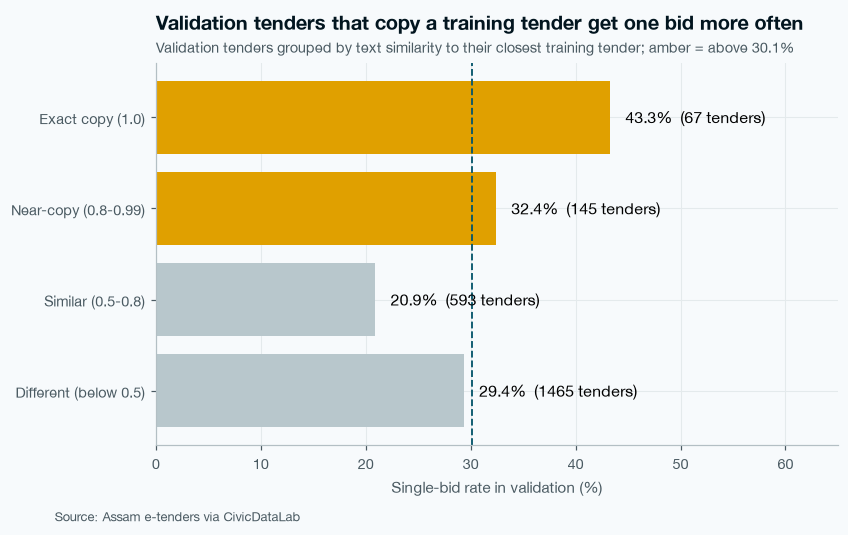

In [37]:
# Chart S6b: single-bid rate by closeness to the nearest training tender
fig, ax = plt.subplots(figsize=(8, 4.5))
colors = np.where(close_table["single-bid %"] > 30.1, ts.SINGLE, ts.NEUTRAL)
bars = ax.barh(close_table.index.astype(str), close_table["single-bid %"], color=colors)

# Labels: rate and number of tenders
labels = []
for rate, n in zip(close_table["single-bid %"], close_table["tenders"]):
    labels.append(str(round(rate, 1)) + "%  (" + str(n) + " tenders)")
ax.bar_label(bars, labels=labels, padding=10)

# Dashed benchmark line, room on the right, x-axis name
ax.axvline(30.1, color=ts.THIRD, linestyle="--", linewidth=1.2)
ax.set_xlim(0, 65)
ax.set_xlabel("Single-bid rate in validation (%)")

# Title, subtitle, source
ts.title(ax, "Validation tenders that copy a training tender get one bid more often",
         subtitle="Validation tenders grouped by text similarity to their closest training tender; amber = above 30.1%")
ts.source(fig)

In [38]:
ts.save_fig(fig, "../reports/figures/S6b_closeness_to_train.png")

## Step 4 · Do words flip over time? (like the departments in S5)

The idea: for each common word, check the single-bid rate of tenders that contain it, in train and in validation.
- A word "points to single bid" if its rate is above the normal rate of that period (train 36.1%, validation 27.8%).
- It "flipped" if it pointed one way in train and the other way in validation.

In [39]:
# Word counter: 1 if the word is in the text, 0 if not; only words in 40+ training texts
word_vec = CountVectorizer(binary=True, min_df=40, stop_words="english", token_pattern=r"\b[a-zA-Z]{3,}\b")

In [40]:
# Learn the word list from training texts, then mark every train and validation text
word_vec.fit(train["text"])
W_tr = word_vec.transform(train["text"])
W_va = word_vec.transform(val["text"])

In [41]:
# The common words
common_words = word_vec.get_feature_names_out()
len(common_words)

169

In [42]:
# Normal single-bid rate (%) of each period
rate_tr = y_tr.mean() * 100
rate_va = y_va.mean() * 100
print("Train:", round(rate_tr, 1), "% | Validation:", round(rate_va, 1), "%")

Train: 36.1 % | Validation: 27.8 %


In [43]:
# One row per word: how many tenders have it and their single-bid rate, in train and validation
rows = []
for j in range(len(common_words)):
    has_tr = W_tr[:, j].toarray().ravel() == 1          # True for training tenders with this word
    has_va = W_va[:, j].toarray().ravel() == 1          # True for validation tenders with this word
    if has_va.sum() < 40:                               # skip words with fewer than 40 validation tenders
        continue
    rows.append({"word": common_words[j],
                 "train n": has_tr.sum(),
                 "train %": y_tr.values[has_tr].mean() * 100,
                 "val n": has_va.sum(),
                 "val %": y_va.values[has_va].mean() * 100})
word_table = pd.DataFrame(rows)

In [44]:
# Number of words kept (40+ tenders in both train and validation)
len(word_table)

69

In [45]:
# Flipped = above normal in one period and below normal in the other
above_tr = word_table["train %"] > rate_tr
above_va = word_table["val %"] > rate_va
word_table["flipped"] = above_tr != above_va
print("Words that flipped:", word_table["flipped"].sum(), "of", len(word_table))

Words that flipped: 46 of 69


In [46]:
# The 12 most common words, biggest first
top_words_table = word_table.sort_values("train n", ascending=False).head(12)
top_words_table.round(1)

,word,train n,train %,val n,val %,flipped
11,construction,1094,39.0,1207,18.6,True
14,district,743,40.1,497,19.7,True
2,assam,681,36.3,376,31.9,False
68,year,528,36.7,725,34.3,False
50,road,468,37.2,827,22.1,True
58,supply,408,28.4,132,26.5,False
61,various,288,23.3,199,26.6,False
67,works,274,32.1,228,46.5,True
38,nos,256,34.0,198,28.3,True
18,group,241,37.3,163,22.1,True


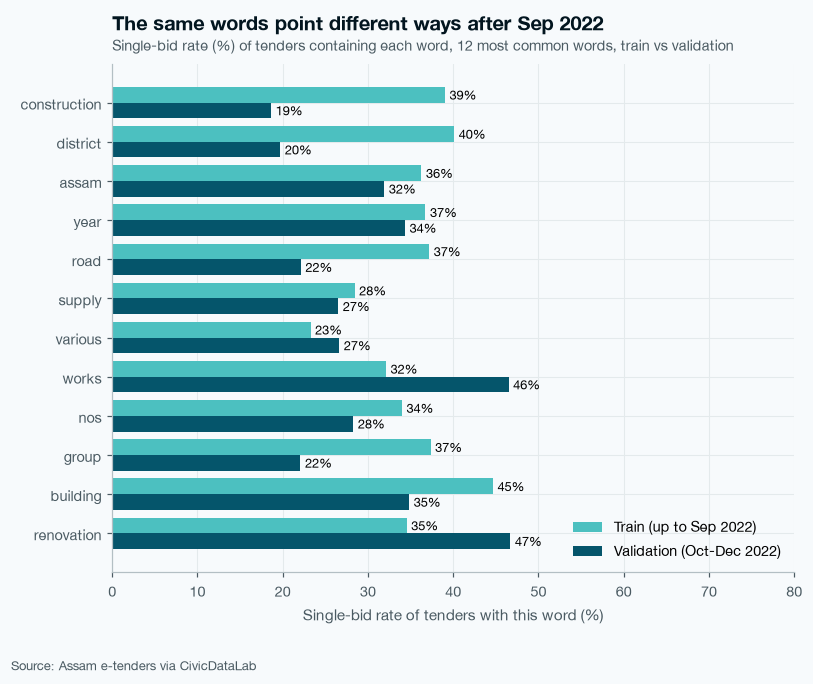

In [47]:
# Chart S6c: train vs validation rate for the 12 most common words (sideways so words fit)
fig, ax = plt.subplots(figsize=(8, 6))
pos = np.arange(len(top_words_table))
b1 = ax.barh(pos - 0.2, top_words_table["train %"], height=0.4, color=ts.BLUES[2], label="Train (up to Sep 2022)")
b2 = ax.barh(pos + 0.2, top_words_table["val %"], height=0.4, color=ts.BLUES[4], label="Validation (Oct-Dec 2022)")

# % labels on the bars
ax.bar_label(b1, fmt="%.0f%%", padding=3, fontsize=8.5)
ax.bar_label(b2, fmt="%.0f%%", padding=3, fontsize=8.5)

# Words on the side, most common on top, x-axis name and room, legend
ax.set_yticks(pos, top_words_table["word"])
ax.invert_yaxis()
ax.set_xlabel("Single-bid rate of tenders with this word (%)")
ax.set_xlim(0, 80)
ax.legend(loc="lower right")

# Title, subtitle, source
ts.title(ax, "The same words point different ways after Sep 2022",
         subtitle="Single-bid rate (%) of tenders containing each word, 12 most common words, train vs validation")
ts.source(fig)

In [48]:
ts.save_fig(fig, "../reports/figures/S6c_word_flip.png")

### Insight · Copies and word flips (Steps 3 and 4)

- Some work is posted many times as separate pieces. The biggest example is one Bodoland irrigation project that was posted 83 times in validation.
- I compared every validation tender with the training tenders. When a validation tender was an exact copy of an old one, it got only one bid 43.3% of the time. Tenders with different words got one bid 29.4% of the time.
- So when the same work comes back, it often gets only one bidder again.
- Then I looked at 69 common words. 46 of them changed direction after Sep 2022.
- For example, tenders with the word "construction" got one bid 39.0% of the time in train, but only 18.6% in validation. "road" went from 37.2% to 22.1%. "works" went the other way, from 32.1% to 46.5%.
- So the change we saw in S5 is not only in departments. Even the words mean something different after Sep 2022.

# Part B · New text clues (each one uses only earlier tenders)

## Step 5 · Tight-wording flags (brand names, OEM, authorised dealer ...)

Audit guides warn that a tender written for one supplier often asks for a brand, a "make", an OEM (original equipment maker) or an "authorised dealer". Fewer suppliers can bid, so it may get only one bid.
Here we check how often these phrases appear in our text, and the single-bid rate when they do.

In [49]:
# Phrases to look for (small letters); the | sign means "or"
tight = {"brand": "brand",
         "make": r"\bmake\b",
         "OEM": r"\boem\b",
         "authorised / authorized": "authori[sz]ed",
         "dealer": "dealer",
         "specific / specification": "specific",
         "genuine / original": "genuine|original",
         "proprietary": "propriet"}

In [50]:
# All texts in small letters so "OEM" and "oem" match
text_low = tv["text"].str.lower()

In [51]:
# One row per phrase: how many train and validation tenders have it, and their single-bid rate
rows = []
for name in tight:
    has = text_low.str.contains(tight[name], regex=True)        # True if the text has the phrase
    has_tr = has[tv["split"] == "train"]                         # train part
    has_va = has[tv["split"] == "val"]                           # validation part
    rows.append({"phrase": name,
                 "train n": has_tr.sum(),
                 "train %": train.loc[has_tr.values, "single_bid"].mean() * 100,
                 "val n": has_va.sum(),
                 "val %": val.loc[has_va.values, "single_bid"].mean() * 100})
tight_table = pd.DataFrame(rows)
tight_table.round(1)

,phrase,train n,train %,val n,val %
0,brand,2,50.0,1,0.0
1,make,3,33.3,3,0.0
2,OEM,1,100.0,2,50.0
3,authorised / authorized,0,NaN,2,50.0
4,dealer,0,NaN,2,50.0
5,specific / specification,3,33.3,1,0.0
6,genuine / original,0,NaN,2,50.0
7,proprietary,0,NaN,0,NaN


In [52]:
# One flag for all phrases together: 1 if the text has ANY tight-wording phrase
all_phrases = "|".join(tight.values())
lab["tight_word"] = lab["text"].str.lower().str.contains(all_phrases, regex=True).astype(int)
print("Tenders with any phrase | train:", lab.loc[lab["split"] == "train", "tight_word"].sum(),
      "| val:", lab.loc[lab["split"] == "val", "tight_word"].sum())

Tenders with any phrase | train: 9 | val: 8


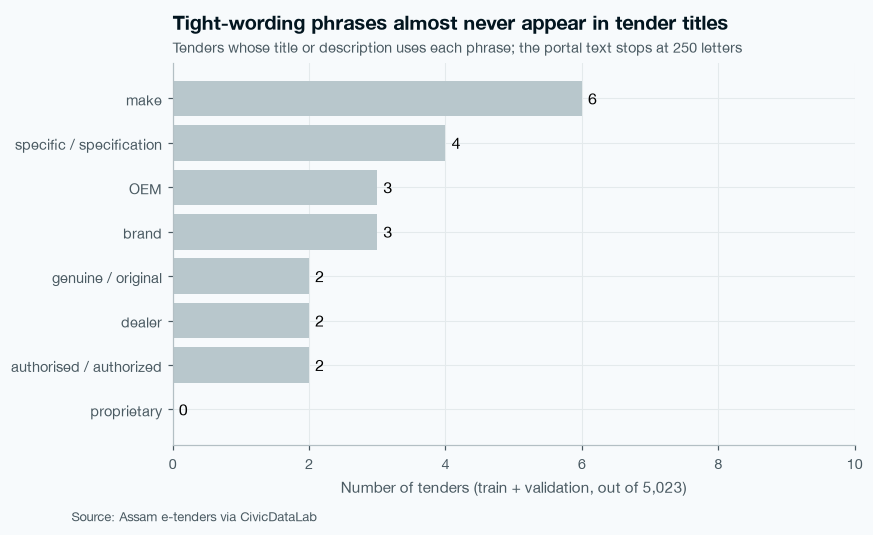

In [53]:
# Chart S6d: how many train + validation tenders use each phrase
tight_table["total"] = tight_table["train n"] + tight_table["val n"]
show = tight_table.sort_values("total")
fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.barh(show["phrase"], show["total"], color=ts.NEUTRAL)

# Count labels, x-axis name, room on the right
ax.bar_label(bars, padding=4)
ax.set_xlabel("Number of tenders (train + validation, out of 5,023)")
ax.set_xlim(0, max(show["total"].max() * 1.3, 10))

# Title, subtitle, source
ts.title(ax, "Tight-wording phrases almost never appear in tender titles",
         subtitle="Tenders whose title or description uses each phrase; the portal text stops at 250 letters")
ts.source(fig)

In [54]:
ts.save_fig(fig, "../reports/figures/S6d_tight_wording.png")

## Step 6 · Smarter re-tender check (similar wording, not only the exact same title)

In S4, retender_60d = 1 when the same department posted the exact same cleaned title 1 to 60 days earlier. In S3 these were the strongest pattern (40% single-bid).
But a re-posted tender can have slightly changed words ("Constn of road at X" vs "Construction of road, X").
New idea: for each tender, look at the same department's tenders from 1 to 60 days earlier and find the most similar title. If the similarity is 0.8 or more (but it is not an exact re-tender), we call it a near re-tender.
This uses only titles and dates (no answers), so it is safe for every set.

In [55]:
# TF-IDF on titles of ALL 39,411 tenders (re-tenders can be any earlier tender, labelled or not)
title_vec = TfidfVectorizer(min_df=2, token_pattern=r"\b[a-zA-Z]{2,}\b")
title_vec.fit(df["title"].fillna(""))

,"token_pattern token_pattern: str, default=r""(?u)\\b\\w\\w+\\b""Regular expression denoting what constitutes a ""token"", only usedif ``analyzer == 'word'``. The default regexp selects tokens of 2or more alphanumeric characters (punctuation is completely ignoredand always treated as a token separator).If there is a capturing group in token_pattern then thecaptured group content, not the entire match, becomes the token.At most one capturing group is permitted.","'\\b[a-zA-Z]{2,}\\b'"
,"min_df min_df: float or int, default=1When building the vocabulary ignore terms that have a documentfrequency strictly lower than the given threshold. This value is alsocalled cut-off in the literature.If float in range of [0.0, 1.0], the parameter represents a proportionof documents, integer absolute counts.This parameter is ignored if vocabulary is not None.",2
,"input input: {'filename', 'file', 'content'}, default='content'- If `'filename'`, the sequence passed as an argument to fit is expected to be a list of filenames that need reading to fetch the raw content to analyze.- If `'file'`, the sequence items must have a 'read' method (file-like object) that is called to fetch the bytes in memory.- If `'content'`, the input is expected to be a sequence of items that can be of type string or byte.",'content'
,"encoding encoding: str, default='utf-8'If bytes or files are given to analyze, this encoding is used todecode.",'utf-8'
,"decode_error decode_error: {'strict', 'ignore', 'replace'}, default='strict'Instruction on what to do if a byte sequence is given to analyze thatcontains characters not of the given `encoding`. By default, it is'strict', meaning that a UnicodeDecodeError will be raised. Othervalues are 'ignore' and 'replace'.",'strict'
,"strip_accents strip_accents: {'ascii', 'unicode'} or callable, default=NoneRemove accents and perform other character normalizationduring the preprocessing step.'ascii' is a fast method that only works on characters that havea direct ASCII mapping.'unicode' is a slightly slower method that works on any characters.None (default) means no character normalization is performed.Both 'ascii' and 'unicode' use NFKD normalization from:func:`unicodedata.normalize`.",None
,"lowercase lowercase: bool, default=TrueConvert all characters to lowercase before tokenizing.",True
,"preprocessor preprocessor: callable, default=NoneOverride the preprocessing (string transformation) stage whilepreserving the tokenizing and n-grams generation steps.Only applies if ``analyzer`` is not callable.",None
,"tokenizer tokenizer: callable, default=NoneOverride the string tokenization step while preserving thepreprocessing and n-grams generation steps.Only applies if ``analyzer == 'word'``.",None
,"analyzer analyzer: {'word', 'char', 'char_wb'} or callable, default='word'Whether the feature should be made of word or character n-grams.Option 'char_wb' creates character n-grams only from text insideword boundaries; n-grams at the edges of words are padded with space.If a callable is passed it is used to extract the sequence of featuresout of the raw, unprocessed input... versionchanged:: 0.21 Since v0.21, if ``input`` is ``'filename'`` or ``'file'``, the data is first read from the file and then passed to the given callable analyzer.",'word'
,"stop_words stop_words: {'english'}, list, default=NoneIf a string, it is passed to _check_stop_list and the appropriate stoplist is returned. 'english' is currently the only supported stringvalue.There are several known issues with 'english' and you shouldconsider an alternative (see :ref:`stop_words`).If a list, that list is assumed to contain stop words, all of whichwill be removed from the resulting tokens.Only applies if ``analyzer == 'word'``.If None, no stop words will be used. In this case, setting `max_df`to a higher value, such as in the range (0.7, 1.0), can automatically detectand filter stop words based on intra corpus document frequency of terms.",None


In [56]:
# Number rows for the titles of our labelled tenders
lab_titles = title_vec.transform(lab["title"])

In [57]:
# One small table per department (so we only search inside the same department)
dept_tables = {}
for name, part in df.groupby("dept_main"):
    dept_tables[name] = part[["published_date", "title"]]

In [58]:
# Helper: best title similarity to the same department's tenders from 1 to 60 days earlier
def near_similarity(i):
    row = lab.iloc[i]                                              # this tender
    others = dept_tables[row["dept_main"]]                         # same department's tenders
    gap = (row["published_date"] - others["published_date"]).dt.days   # days between them
    earlier = others[(gap >= 1) & (gap <= 60)]                     # only 1 to 60 days earlier
    if len(earlier) == 0:                                          # nothing earlier = similarity 0
        return 0.0
    sims = cosine_similarity(lab_titles[i], title_vec.transform(earlier["title"]))   # compare titles
    return sims.max()                                              # the closest one

In [59]:
# Run the helper for every labelled tender (takes about half a minute)
near_sim = []
for i in range(len(lab)):
    near_sim.append(near_similarity(i))
lab["near_sim"] = near_sim

In [60]:
# Near re-tender = very similar title (0.8+) but NOT already an exact re-tender
lab["near_retender"] = ((lab["near_sim"] >= 0.8) & (lab["retender_60d"] == 0)).astype(int)

In [61]:
# Three groups: exact re-tender, near re-tender, new tender
lab["retender_group"] = "New tender"
lab.loc[lab["near_retender"] == 1, "retender_group"] = "Near re-tender (similar title)"
lab.loc[lab["retender_60d"] == 1, "retender_group"] = "Exact re-tender (same title)"

In [62]:
# Train and validation again, so they include the new columns
tv = lab[lab["split"] != "test"]
train = lab[lab["split"] == "train"]
val = lab[lab["split"] == "val"]

In [63]:
# Number of tenders and single-bid rate (%) in each group, train vs validation
order = ["Exact re-tender (same title)", "Near re-tender (similar title)", "New tender"]
retender_table = pd.DataFrame(index=order)
retender_table["train n"] = train["retender_group"].value_counts()
retender_table["train %"] = train.groupby("retender_group")["single_bid"].mean() * 100
retender_table["val n"] = val["retender_group"].value_counts()
retender_table["val %"] = val.groupby("retender_group")["single_bid"].mean() * 100
retender_table.round(1)

,train n,train %,val n,val %
Exact re-tender (same title),87,35.6,48,58.3
Near re-tender (similar title),338,32.8,639,20.3
New tender,2328,36.6,1583,29.8


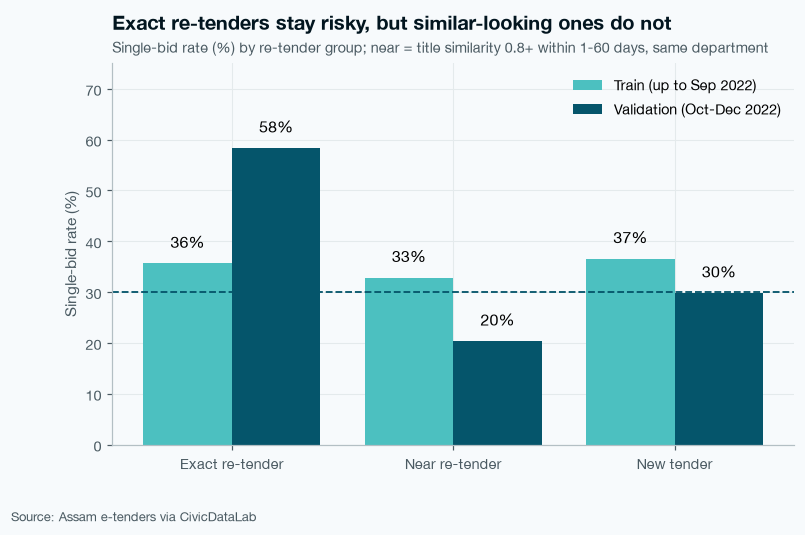

In [64]:
# Chart S6e: single-bid rate by re-tender group, train vs validation
fig, ax = plt.subplots(figsize=(8, 4.5))
pos = np.arange(len(retender_table))
b1 = ax.bar(pos - 0.2, retender_table["train %"], width=0.4, color=ts.BLUES[2], label="Train (up to Sep 2022)")
b2 = ax.bar(pos + 0.2, retender_table["val %"], width=0.4, color=ts.BLUES[4], label="Validation (Oct-Dec 2022)")

# % labels, dashed 30.1% line
ax.bar_label(b1, fmt="%.0f%%", padding=8)
ax.bar_label(b2, fmt="%.0f%%", padding=8)
ax.axhline(30.1, color=ts.THIRD, linestyle="--", linewidth=1.2)

# Group names, y-axis name, room, legend
ax.set_xticks(pos, ["Exact re-tender", "Near re-tender", "New tender"])
ax.set_ylabel("Single-bid rate (%)")
ax.set_ylim(0, 75)
ax.legend(loc="upper right")

# Title, subtitle, source
ts.title(ax, "Exact re-tenders stay risky, but similar-looking ones do not",
         subtitle="Single-bid rate (%) by re-tender group; near = title similarity 0.8+ within 1-60 days, same department")
ts.source(fig)

In [65]:
ts.save_fig(fig, "../reports/figures/S6e_near_retender.png")

## Step 7 · "Tenders like this one" rate

The idea: like dept_rate, but by type of work instead of office.
For each tender we find the 20 most similar EARLIER training tenders (by text) and take their single-bid rate.
- Training tenders: only training tenders published before them (no peeking at the future).
- Validation and test tenders: all training tenders (all of them are earlier).
Later this gives a nice line for the app: "Similar past tenders got one bid 45% of the time".

In [66]:
# TF-IDF on the full text, word list learned from training texts only
text_vec = TfidfVectorizer(min_df=2, stop_words="english", token_pattern=r"\b[a-zA-Z]{3,}\b")
text_vec.fit(train["text"])

,"stop_words stop_words: {'english'}, list, default=NoneIf a string, it is passed to _check_stop_list and the appropriate stoplist is returned. 'english' is currently the only supported stringvalue.There are several known issues with 'english' and you shouldconsider an alternative (see :ref:`stop_words`).If a list, that list is assumed to contain stop words, all of whichwill be removed from the resulting tokens.Only applies if ``analyzer == 'word'``.If None, no stop words will be used. In this case, setting `max_df`to a higher value, such as in the range (0.7, 1.0), can automatically detectand filter stop words based on intra corpus document frequency of terms.",'english'
,"token_pattern token_pattern: str, default=r""(?u)\\b\\w\\w+\\b""Regular expression denoting what constitutes a ""token"", only usedif ``analyzer == 'word'``. The default regexp selects tokens of 2or more alphanumeric characters (punctuation is completely ignoredand always treated as a token separator).If there is a capturing group in token_pattern then thecaptured group content, not the entire match, becomes the token.At most one capturing group is permitted.","'\\b[a-zA-Z]{3,}\\b'"
,"min_df min_df: float or int, default=1When building the vocabulary ignore terms that have a documentfrequency strictly lower than the given threshold. This value is alsocalled cut-off in the literature.If float in range of [0.0, 1.0], the parameter represents a proportionof documents, integer absolute counts.This parameter is ignored if vocabulary is not None.",2
,"input input: {'filename', 'file', 'content'}, default='content'- If `'filename'`, the sequence passed as an argument to fit is expected to be a list of filenames that need reading to fetch the raw content to analyze.- If `'file'`, the sequence items must have a 'read' method (file-like object) that is called to fetch the bytes in memory.- If `'content'`, the input is expected to be a sequence of items that can be of type string or byte.",'content'
,"encoding encoding: str, default='utf-8'If bytes or files are given to analyze, this encoding is used todecode.",'utf-8'
,"decode_error decode_error: {'strict', 'ignore', 'replace'}, default='strict'Instruction on what to do if a byte sequence is given to analyze thatcontains characters not of the given `encoding`. By default, it is'strict', meaning that a UnicodeDecodeError will be raised. Othervalues are 'ignore' and 'replace'.",'strict'
,"strip_accents strip_accents: {'ascii', 'unicode'} or callable, default=NoneRemove accents and perform other character normalizationduring the preprocessing step.'ascii' is a fast method that only works on characters that havea direct ASCII mapping.'unicode' is a slightly slower method that works on any characters.None (default) means no character normalization is performed.Both 'ascii' and 'unicode' use NFKD normalization from:func:`unicodedata.normalize`.",None
,"lowercase lowercase: bool, default=TrueConvert all characters to lowercase before tokenizing.",True
,"preprocessor preprocessor: callable, default=NoneOverride the preprocessing (string transformation) stage whilepreserving the tokenizing and n-grams generation steps.Only applies if ``analyzer`` is not callable.",None
,"tokenizer tokenizer: callable, default=NoneOverride the string tokenization step while preserving thepreprocessing and n-grams generation steps.Only applies if ``analyzer == 'word'``.",None
,"analyzer analyzer: {'word', 'char', 'char_wb'} or callable, default='word'Whether the feature should be made of word or character n-grams.Option 'char_wb' creates character n-grams only from text insideword boundaries; n-grams at the edges of words are padded with space.If a callable is passed it is used to extract the sequence of featuresout of the raw, unprocessed input... versionchanged:: 0.21 Since v0.21, if ``input`` is ``'filename'`` or ``'file'``, the data is first read from the file and then passed to the given callable analyzer.",'word'


In [67]:
# Number rows for training texts and for all labelled texts
T_train = text_vec.transform(train["text"])
T_all = text_vec.transform(lab["text"])

In [68]:
# Similarity of every labelled tender to every training tender (rows = all, columns = training)
sim_to_train = cosine_similarity(T_all, T_train)
sim_to_train.shape

(6790, 2753)

In [69]:
# Training answers and dates as plain arrays
train_answers = train["single_bid"].values
train_dates = train["published_date"].values

In [70]:
# Helper: single-bid rate of the 20 most similar earlier training tenders for row i of lab
def similar_rate(i):
    sims = sim_to_train[i]                                        # similarity to each training tender
    earlier = train_dates < lab["published_date"].values[i]       # True for training tenders published before this one
    if earlier.sum() == 0:                                        # no earlier tender: use the overall training rate
        return 0.3607
    sims = sims[earlier]                                          # keep only earlier ones
    answers = train_answers[earlier]
    top20 = np.argsort(-sims, kind="stable")[:20]                 # positions of the 20 most similar
    return answers[top20].mean()                                  # their single-bid rate

In [71]:
# Run it for every labelled tender (takes a few seconds)
rates = []
for i in range(len(lab)):
    rates.append(similar_rate(i))
lab["similar_rate"] = rates

In [72]:
# Train and validation again with the new column
tv = lab[lab["split"] != "test"]
train = lab[lab["split"] == "train"]
val = lab[lab["split"] == "val"]

In [73]:
# Does the clue alone work? ROC-AUC in train and validation (0.5 = coin toss)
print("Train ROC:", round(roc_auc_score(y_tr, train["similar_rate"]), 3),
      "| Val ROC:", round(roc_auc_score(y_va, val["similar_rate"]), 3))

Train ROC: 0.553 | Val ROC: 0.484


In [74]:
# Bands: low (under 25%), medium (25-45%), high (over 45%)
band = pd.cut(tv["similar_rate"], bins=[-0.01, 0.25, 0.45, 1.0], labels=["Low (under 25%)", "Medium (25-45%)", "High (over 45%)"])

In [75]:
# Single-bid rate (%) in each band, train vs validation
similar_table = pd.DataFrame()
similar_table["train n"] = band[tv["split"] == "train"].value_counts(sort=False)
similar_table["train %"] = train.groupby(band[tv["split"] == "train"], observed=True)["single_bid"].mean() * 100
similar_table["val n"] = band[tv["split"] == "val"].value_counts(sort=False)
similar_table["val %"] = val.groupby(band[tv["split"] == "val"], observed=True)["single_bid"].mean() * 100
similar_table.round(1)

,train n,train %,val n,val %
similar_rate,,,,
Low (under 25%),670,28.8,603,33.0
Medium (25-45%),1345,37.3,1342,24.5
High (over 45%),738,40.4,325,31.4


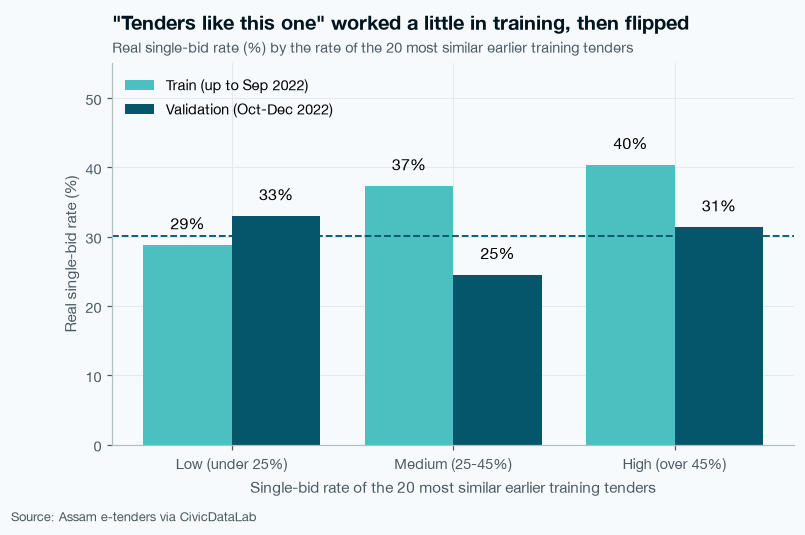

In [76]:
# Chart S6f: single-bid rate by "tenders like this one" band, train vs validation
fig, ax = plt.subplots(figsize=(8, 4.5))
pos = np.arange(len(similar_table))
b1 = ax.bar(pos - 0.2, similar_table["train %"], width=0.4, color=ts.BLUES[2], label="Train (up to Sep 2022)")
b2 = ax.bar(pos + 0.2, similar_table["val %"], width=0.4, color=ts.BLUES[4], label="Validation (Oct-Dec 2022)")

# % labels and the dashed 30.1% line
ax.bar_label(b1, fmt="%.0f%%", padding=8)
ax.bar_label(b2, fmt="%.0f%%", padding=8)
ax.axhline(30.1, color=ts.THIRD, linestyle="--", linewidth=1.2)

# Band names, y-axis name, room, legend
ax.set_xticks(pos, similar_table.index)
ax.set_xlabel("Single-bid rate of the 20 most similar earlier training tenders")
ax.set_ylabel("Real single-bid rate (%)")
ax.set_ylim(0, 55)
ax.legend(loc="upper left")

# Title, subtitle, source
ts.title(ax, "\"Tenders like this one\" worked a little in training, then flipped",
         subtitle="Real single-bid rate (%) by the rate of the 20 most similar earlier training tenders")
ts.source(fig)

In [77]:
ts.save_fig(fig, "../reports/figures/S6f_similar_tenders.png")

### Insight · New text clues (Steps 5 to 7)

- Brand and dealer words: I looked for words like brand, OEM and authorised dealer. Only 17 tenders used any of them, which is too few to test. These words are usually in the attached documents, not in the short title.
- Exact re-tenders (same title again within 60 days) were still risky. They got one bid 58.3% of the time in validation.
- Tenders with a similar title (not the same) were not risky. They got one bid only 20.3% of the time in validation. Most of them are pieces of the same big work posted close together, not real re-tenders.
- "Tenders like this one": for each tender I looked at the 20 most similar older tenders and took their single-bid rate. It helped a little in train, but in validation it did not work (no better than a coin toss).
- So none of the 3 new text clues helped on validation.

## Step 8 · Work types: what changed in December?

In S5 we saw December 2022 had a big drop (19.3% single-bid) and it was mostly real inside departments. Now we ask: did the TYPE of work change?
We give each tender one simple work type using words in its text. The first group that matches wins (so a "road bridge" is Roads, not Water).

In [78]:
# Work types and the words that mark them (checked in this order)
work_words = {"Roads and bridges": ["road", "bridge", "culvert", "pmgsy"],
              "Water, flood and irrigation": ["flood", "embankment", "river", "irrigation", "water", "drain", "bund", "erosion", "sluice"],
              "Power and electrical": ["electric", "power", "solar", "transformer", "substation", "light"],
              "Health": ["hospital", "health", "medical", "phc", "chc", "bedded", "medicine", "drug", "ward"],
              "Schools and hostels": ["school", "college", "hostel", "classroom", "class room", "university", "anganwadi"],
              "Buildings and offices": ["building", "office", "quarter", "house", "hall", "residence", "complex", "construction of"],
              "Supply of goods": ["supply", "procurement", "purchase", "printing"]}

In [79]:
# Helper: the work type of one text (first group with a matching word), else "Other"
def work_type(text):
    text = text.lower()                         # small letters
    for group in work_words:                    # check groups in order
        for w in work_words[group]:             # each word of that group
            if w in text:                       # found a word
                return group
    return "Other"                              # no word found

In [80]:
# Work type for every labelled tender
lab["work_type"] = lab["text"].apply(work_type)
lab["work_type"].value_counts()

work_type
Roads and bridges              1864
Buildings and offices          1138
Other                           978
Water, flood and irrigation     776
Health                          709
Supply of goods                 569
Schools and hostels             465
Power and electrical            291
Name: count, dtype: int64

In [81]:
# Train and validation again, plus a period column: Train, Oct-Nov, Dec
tv = lab[lab["split"] != "test"].copy()
train = lab[lab["split"] == "train"]
val = lab[lab["split"] == "val"]
tv["period"] = "Train"
tv.loc[(tv["split"] == "val") & (tv["published_date"].dt.month != 12), "period"] = "Oct-Nov"
tv.loc[(tv["split"] == "val") & (tv["published_date"].dt.month == 12), "period"] = "Dec"

In [82]:
# Share (%) of each work type in each period (each column adds up to 100)
mix = pd.crosstab(tv["work_type"], tv["period"], normalize="columns") * 100
mix = mix[["Train", "Oct-Nov", "Dec"]]
mix.round(1)

period,Train,Oct-Nov,Dec
work_type,,,
Buildings and offices,23.0,13.1,8.4
Health,8.9,13.2,18.8
Other,17.1,14.2,5.2
Power and electrical,5.6,3.5,3.2
Roads and bridges,18.4,26.0,48.0
Schools and hostels,7.2,6.7,5.4
Supply of goods,11.4,5.8,2.1
"Water, flood and irrigation",8.5,17.5,8.8


In [83]:
# Single-bid rate (%) of each work type in each period
type_rate = tv.groupby(["work_type", "period"])["single_bid"].mean().unstack() * 100
type_rate = type_rate[["Train", "Oct-Nov", "Dec"]]
type_rate.round(1)

period,Train,Oct-Nov,Dec
work_type,,,
Buildings and offices,44.7,36.5,36.9
Health,34.7,18.8,9.1
Other,36.2,40.9,33.3
Power and electrical,29.7,24.3,38.5
Roads and bridges,36.4,39.2,14.5
Schools and hostels,30.5,47.1,18.2
Supply of goods,28.4,29.5,30.8
"Water, flood and irrigation",32.5,48.9,33.3


In [84]:
# Number of tenders, to see which rates are based on very few tenders
pd.crosstab(tv["work_type"], tv["period"])[["Train", "Oct-Nov", "Dec"]]

period,Train,Oct-Nov,Dec
work_type,,,
Buildings and offices,633,137,103
Health,245,138,230
Other,470,149,63
Power and electrical,155,37,39
Roads and bridges,506,273,586
Schools and hostels,197,70,66
Supply of goods,313,61,26
"Water, flood and irrigation",234,184,108


In [85]:
# If December had the Oct-Nov work-type mix, what would its rate be?
dec_rate = type_rate["Dec"]
octnov_mix = mix["Oct-Nov"] / 100
mixed = (dec_rate * octnov_mix).sum() / octnov_mix.sum()
print("Dec real:", round(tv.loc[tv["period"] == "Dec", "single_bid"].mean() * 100, 1), "%",
      "| Dec with Oct-Nov work mix:", round(mixed, 1), "%",
      "| Oct-Nov real:", round(tv.loc[tv["period"] == "Oct-Nov", "single_bid"].mean() * 100, 1), "%")

Dec real: 19.3 % | Dec with Oct-Nov work mix: 24.7 % | Oct-Nov real: 37.6 %


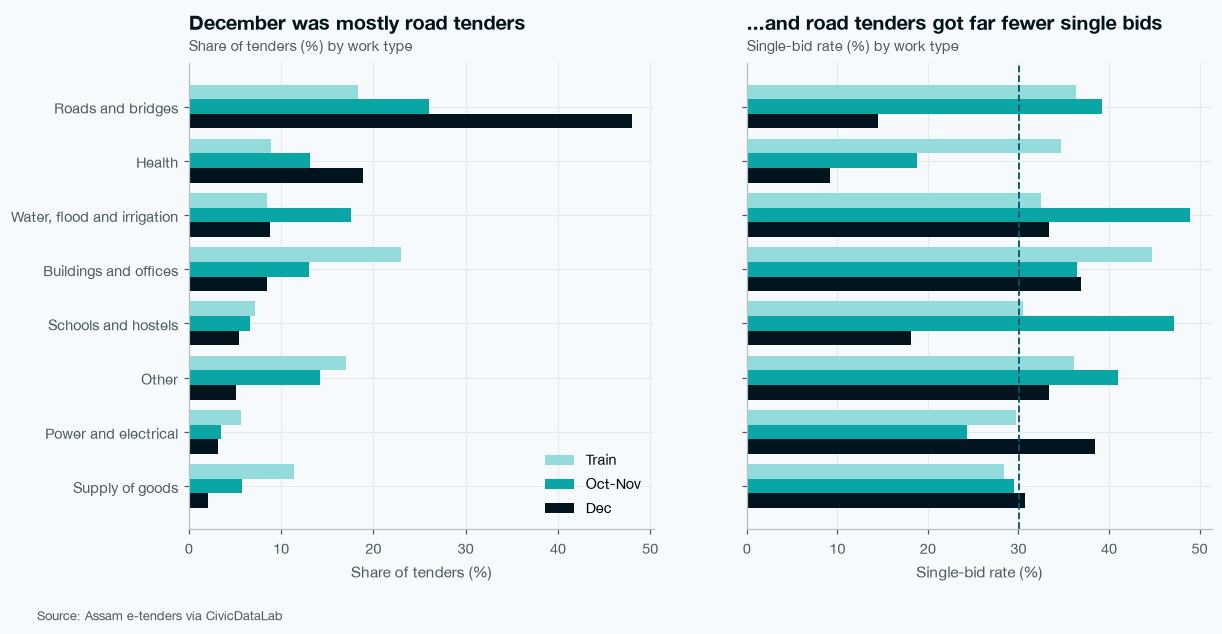

In [86]:
# Chart S6g: two panels - left = share of tenders, right = single-bid rate, for each work type
order = mix.sort_values("Dec").index
pos = np.arange(len(order))
fig, axes = plt.subplots(1, 2, figsize=(12, 5.5), sharey=True)
colors = [ts.BLUES[1], ts.BLUES[3], ts.BLUES[5]]

# Left panel: share of tenders in each period
for k, period in enumerate(["Train", "Oct-Nov", "Dec"]):
    axes[0].barh(pos + 0.27 - k * 0.27, mix.loc[order, period], height=0.27, color=colors[k], label=period)
axes[0].set_yticks(pos, order)
axes[0].set_xlabel("Share of tenders (%)")
axes[0].legend(loc="lower right")
ts.title(axes[0], "December was mostly road tenders", subtitle="Share of tenders (%) by work type")

# Right panel: single-bid rate in each period, with the dashed 30.1% line
for k, period in enumerate(["Train", "Oct-Nov", "Dec"]):
    axes[1].barh(pos + 0.27 - k * 0.27, type_rate.loc[order, period], height=0.27, color=colors[k], label=period)
axes[1].axvline(30.1, color=ts.THIRD, linestyle="--", linewidth=1.2)
axes[1].set_xlabel("Single-bid rate (%)")
ts.title(axes[1], "...and road tenders got far fewer single bids", subtitle="Single-bid rate (%) by work type")

# Source line
ts.source(fig)

In [87]:
ts.save_fig(fig, "../reports/figures/S6g_work_types_december.png")

## Step 9 · Drift test: can the words alone tell old tenders from new ones?

Same idea as S5 Step 5, but with words only. We hide the dates and ask a model: "is this tender from train or from validation?"
- ROC near 0.5 = the words look the same in both periods.
- ROC near 1 = the words changed a lot (new schemes, new kinds of work).

In [88]:
# Tools to cut the data into 5 parts, score each part, and keep the guesses
from sklearn.model_selection import StratifiedKFold
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import roc_curve

In [89]:
# Words as numbers (letters only, so year numbers like 2022-23 cannot give the answer away)
drift_vec = TfidfVectorizer(min_df=5, stop_words="english", token_pattern=r"\b[a-zA-Z]{3,}\b")
X_drift = drift_vec.fit_transform(tv["text"])

In [90]:
# Answer for this test only: 1 = validation tender, 0 = train tender
is_new = (tv["split"] == "val").astype(int)

In [91]:
# A Logistic Regression and 5 shuffled parts
drift_model = LogisticRegression(max_iter=3000)
folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

In [92]:
# Train on 4 parts, score the 5th, 5 times; then the average ROC-AUC
drift_scores = cross_val_score(drift_model, X_drift, is_new, cv=folds, scoring="roc_auc")
print("Old vs new ROC-AUC from words:", round(drift_scores.mean(), 3))

Old vs new ROC-AUC from words: 0.913


In [93]:
# The guess for each tender when it was in the held-out part (for the ROC curve chart)
drift_guess = cross_val_predict(drift_model, X_drift, is_new, cv=folds, method="predict_proba")[:, 1]

In [94]:
# Which words give the period away? Train once on everything and look at the weights
drift_model.fit(X_drift, is_new)
drift_weights = pd.Series(drift_model.coef_[0], index=drift_vec.get_feature_names_out())
print("Words of OLD tenders:", list(drift_weights.sort_values().head(10).index))
print("Words of NEW tenders:", list(drift_weights.sort_values().tail(10).index))

Words of OLD tenders: ['apart', 'sdrf', 'upgrade', 'cidf', 'places', 'untied', 'stadium', 'xxvii', 'ado', 'knowledge']
Words of NEW tenders: ['contractors', 'maint', 'mantrir', 'secondary', 'aop', 'mukhya', 'health', 'mmppna', 'buildingless', 'iii']


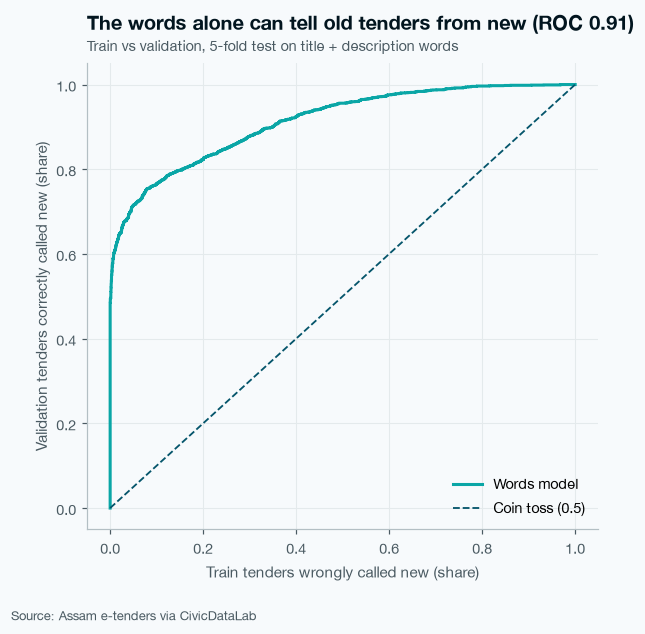

In [95]:
# Chart S6h: ROC curve of the old-vs-new test
fpr, tpr, cuts = roc_curve(is_new, drift_guess)
fig, ax = plt.subplots(figsize=(6, 5.5))
ax.plot(fpr, tpr, color=ts.MULTI, label="Words model")

# Coin-toss line (a model that cannot tell the periods apart)
ax.plot([0, 1], [0, 1], color=ts.THIRD, linestyle="--", linewidth=1.2, label="Coin toss (0.5)")

# Axis names and legend
ax.set_xlabel("Train tenders wrongly called new (share)")
ax.set_ylabel("Validation tenders correctly called new (share)")
ax.legend(loc="lower right")

# Title with the score, subtitle, source
ts.title(ax, "The words alone can tell old tenders from new (ROC " + str(round(drift_scores.mean(), 2)) + ")",
         subtitle="Train vs validation, 5-fold test on title + description words")
ts.source(fig)

In [96]:
ts.save_fig(fig, "../reports/figures/S6h_text_drift_roc.png")

### Insight · Work types and text drift (Steps 8 and 9)

- I gave each tender a simple work type using its words, like roads, health, schools or buildings.
- December 2022 was very different. Almost half of December tenders (48.0%) were road work. In Oct-Nov it was 26.0%.
- Road tenders also got far fewer single bids in December: 14.5%, compared with 39.2% in Oct-Nov. Health tenders went from 34.7% in train to only 9.1% in December.
- Even if December had the same mix of work as Oct-Nov, its rate would be 24.7%, still much lower than Oct-Nov (37.6%). So the drop happened inside each type of work, not only because the mix changed.
- I also tested if a model can tell old tenders from new ones using only the words. It could, very easily (score 0.913, where 0.5 means it cannot tell).
- The words that gave it away were names of government schemes. Old tenders talk about APART, SDRF and CIDF. New tenders talk about Mukhya Mantrir and MMPPNA.
- So the tenders really changed after Sep 2022: new schemes came in, and December had a big wave of road work. This is the reason behind the drift.

# Part C · Prediction with text

## Step 10 · Score helpers and benchmarks (same as S5)

In [97]:
# Helper 1: share (%) of all single-bid tenders found in the riskiest top part
def capture(y, risk, share):
    t = pd.DataFrame({"real": y.values, "risk": risk})              # answers next to risk scores
    t = t.sort_values("risk", ascending=False, kind="stable")       # riskiest first (ties keep date order)
    top = t.head(int(len(t) * share))                               # keep the top part, e.g. 20%
    return top["real"].sum() / t["real"].sum() * 100                # caught / all single-bids

In [98]:
# Helper 2: all scores for one model as one row of the results table
def score_row(name, y, risk):
    row = {"model": name}                                           # model name first
    row["PR-AUC"] = round(average_precision_score(y, risk), 3)      # ranking score for single-bids
    row["ROC-AUC"] = round(roc_auc_score(y, risk), 3)               # 0.5 = coin toss
    row["capture top 10%"] = round(capture(y, risk, 0.1), 1)        # caught when checking 10%
    row["capture top 20%"] = round(capture(y, risk, 0.2), 1)        # caught when checking 20%
    return row

In [99]:
# Helper 3 (from S5): scale, train Logistic Regression, return risk scores
def lr_risk(learn, answers, score, clues):
    scaler = StandardScaler().fit(learn[clues])                          # learn scale from learning rows
    model = LogisticRegression(class_weight="balanced", max_iter=3000)   # the model
    model.fit(scaler.transform(learn[clues]), answers)                   # scale and learn
    return model.predict_proba(scaler.transform(score[clues]))[:, 1]     # risk scores

In [100]:
# Empty results list (one row per method) and a box to keep every method's risk scores by name
results = []
risks = {}

In [101]:
# Random: every tender gets a random risk (seed 42, same as S5)
rng = np.random.default_rng(42)
risks["Random"] = rng.random(len(val))
results.append(score_row("Random", y_va, risks["Random"]))

In [102]:
# Rule B from S5: quick re-tenders first, then by department rate
risks["Rule B: re-tender then dept"] = (val["retender_60d"] + val["dept_rate"] / 10).values
results.append(score_row("Rule B: re-tender then dept", y_va, risks["Rule B: re-tender then dept"]))

In [103]:
# S5 numbers clues only (LogReg, 34 clues, learned once from train) to compare with text
risks["S5 LogReg (34 clues)"] = lr_risk(train, y_tr, val, full)
results.append(score_row("S5 LogReg (34 clues)", y_va, risks["S5 LogReg (34 clues)"]))
pd.DataFrame(results)

,model,PR-AUC,ROC-AUC,capture top 10%,capture top 20%
0,Random,0.288,0.514,11.1,19.8
1,Rule B: re-tender then dept,0.268,0.431,12.5,14.6
2,S5 LogReg (34 clues),0.245,0.417,7.3,15.2


## Step 11 · TF-IDF + Logistic Regression

TF-IDF turns every text into a long row of numbers, one column per word. Then Logistic Regression gives each word a weight, like it gave each clue a weight in S5.

| Part | Simple meaning |
|---|---|
| `min_df=5` | a word must be in 5+ training texts to get a column |
| `vec.fit(train["text"])` | learn the word list from TRAINING only |
| `vec.transform(...)` | turn texts into number rows |
| `X_tr.shape` | (number of tenders, number of word columns) |
| `class_weight="balanced"` | single-bid tenders count more because there are fewer of them |

### 11a · TF-IDF alone, written out step by step

In [104]:
# 1. The TF-IDF tool (words with 3+ letters, no filler words, in 5+ training texts)
vec = TfidfVectorizer(min_df=5, stop_words="english", token_pattern=r"\b[a-zA-Z]{3,}\b")

In [105]:
# 2. Learn the word list from training texts only
vec.fit(train["text"])
len(vec.get_feature_names_out())

901

In [106]:
# 3. Turn train and validation texts into number rows
X_tr = vec.transform(train["text"])
X_va = vec.transform(val["text"])
X_tr.shape

(2753, 901)

In [107]:
# 4. The model
text_lr = LogisticRegression(class_weight="balanced", max_iter=3000)

In [108]:
# 5. Learn from training texts and their answers
text_lr.fit(X_tr, y_tr)

,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",3000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Defaul

In [109]:
# 6. Risk score (0 to 1) for every validation tender
risks["TF-IDF alone"] = text_lr.predict_proba(X_va)[:, 1]

In [110]:
# 7. Score it and add the row
results.append(score_row("TF-IDF alone", y_va, risks["TF-IDF alone"]))
pd.DataFrame(results).tail(1)

,model,PR-AUC,ROC-AUC,capture top 10%,capture top 20%
3,TF-IDF alone,0.274,0.474,9.2,19.8


### 11b · The same steps as one helper, with an option to add number clues

To use words AND number clues together, we glue the TF-IDF columns and the scaled clue columns side by side (`hstack`).

| Part | Simple meaning |
|---|---|
| `clues=None` | no number clues, words only |
| `csr_matrix(...)` | puts the scaled clues in the same table type as TF-IDF |
| `hstack([A, B])` | glue table A and table B side by side |
| `.tocsr()` | tidy the glued table so the model can read it fast |

In [111]:
# Helper 4: TF-IDF (+ optional number clues) -> Logistic Regression -> risk scores
def tfidf_risk(learn, answers, score, clues=None):
    v = TfidfVectorizer(min_df=5, stop_words="english", token_pattern=r"\b[a-zA-Z]{3,}\b")   # 1. the tool
    X_learn = v.fit_transform(learn["text"])                                # 2 + 3. word list from learning rows
    X_score = v.transform(score["text"])                                    # 3. same word list for scoring rows
    if clues is not None:                                                   # add number clues if asked
        scaler = StandardScaler().fit(learn[clues])                         # scale learned from learning rows
        X_learn = hstack([X_learn, csr_matrix(scaler.transform(learn[clues]))]).tocsr()   # glue words + clues
        X_score = hstack([X_score, csr_matrix(scaler.transform(score[clues]))]).tocsr()
    model = LogisticRegression(class_weight="balanced", max_iter=3000)      # 4. the model
    model.fit(X_learn, answers)                                             # 5. learn
    return model.predict_proba(X_score)[:, 1]                               # 6. risk scores

In [112]:
# Check: the helper gives the same score as the step-by-step version
round(average_precision_score(y_va, tfidf_risk(train, y_tr, val)), 3)

0.274

In [113]:
# TF-IDF + the 7 base clues
risks["TF-IDF + 7 clues"] = tfidf_risk(train, y_tr, val, base)
results.append(score_row("TF-IDF + 7 clues", y_va, risks["TF-IDF + 7 clues"]))

In [114]:
# TF-IDF + all 34 clues
risks["TF-IDF + 34 clues"] = tfidf_risk(train, y_tr, val, full)
results.append(score_row("TF-IDF + 34 clues", y_va, risks["TF-IDF + 34 clues"]))
pd.DataFrame(results).tail(3)

,model,PR-AUC,ROC-AUC,capture top 10%,capture top 20%
3,TF-IDF alone,0.274,0.474,9.2,19.8
4,TF-IDF + 7 clues,0.267,0.452,9.8,20.3
5,TF-IDF + 34 clues,0.264,0.460,7.9,15.7


## Step 12 · Which words push a tender towards or away from single bid?

In [115]:
# One weight per word from the step-by-step model (plus = towards single bid, minus = away)
word_weights = pd.Series(text_lr.coef_[0], index=vec.get_feature_names_out())

In [116]:
# 10 words pushing most towards single bid, and 10 pushing most away
towards = word_weights.sort_values().tail(10)
away = word_weights.sort_values().head(10)
print("Towards single bid:", list(towards.index[::-1]))
print("Away from single bid:", list(away.index))

Towards single bid: ['scheme', 'points', 'fighting', 'breach', 'darrang', 'capacity', 'market', 'preparation', 'engagement', 'jorhat']
Away from single bid: ['various', 'guwahati', 'rate', 'lines', 'drain', 'lkr', 'municipal', 'operation', 'equipment', 'related']


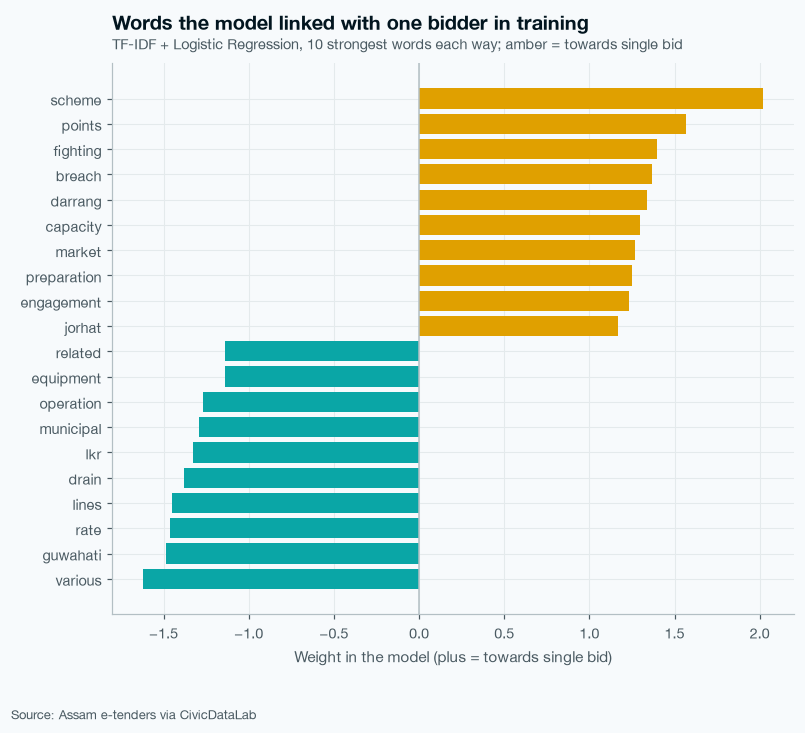

In [117]:
# Chart S6i: the 20 strongest words (amber = towards single bid, teal = away)
top = pd.concat([away, towards])
colors = np.where(top > 0, ts.SINGLE, ts.MULTI)
fig, ax = plt.subplots(figsize=(8, 6.5))
ax.barh(top.index, top.values, color=colors)

# Zero line and x-axis name
ax.axvline(0, color=ts.AXIS, linewidth=1)
ax.set_xlabel("Weight in the model (plus = towards single bid)")

# Title, subtitle, source
ts.title(ax, "Words the model linked with one bidder in training",
         subtitle="TF-IDF + Logistic Regression, 10 strongest words each way; amber = towards single bid")
ts.source(fig)

In [118]:
ts.save_fig(fig, "../reports/figures/S6i_top_words.png")

In [119]:
# Do the top "towards" words still point to single bid in validation? (rate % of tenders with the word)
for w in list(towards.index[::-1])[:6]:
    has_tr = train["text"].str.lower().str.contains(r"\b" + w + r"\b", regex=True)
    has_va = val["text"].str.lower().str.contains(r"\b" + w + r"\b", regex=True)
    print(w, "| train:", has_tr.sum(), "tenders,", round(train.loc[has_tr, "single_bid"].mean() * 100, 1),
          "% | val:", has_va.sum(), "tenders,", round(val.loc[has_va, "single_bid"].mean() * 100, 1), "%")

scheme | train: 162 tenders, 50.6 % | val: 139 tenders, 21.6 %
points | train: 16 tenders, 81.2 % | val: 26 tenders, 42.3 %
fighting | train: 13 tenders, 92.3 % | val: 1 tenders, 0.0 %
breach | train: 11 tenders, 81.8 % | val: 34 tenders, 32.4 %
darrang | train: 20 tenders, 70.0 % | val: 24 tenders, 12.5 %
capacity | train: 17 tenders, 58.8 % | val: 10 tenders, 20.0 %


### Insight · TF-IDF models and top words (Steps 10 to 12)

- TF-IDF turns each text into numbers, one number per word. Then the model learns which words go with single bids.
- The words-only model got PR-AUC 0.274 and caught 19.8% of single-bid tenders when checking the top 20%. That is the same as random checking (0.288 and 19.8%).
- Adding the number clues from S5 did not make it better.
- In training, the words that pointed to one bidder were "scheme", "points", "breach" and "darrang". Words that pointed to more bidders were "various", "guwahati", "drain" and "municipal".
- But these words did not keep their meaning. "scheme" was 50.6% single-bid in train and only 21.6% in validation. "darrang" went from 70.0% to 12.5%.
- So the model learned the old pattern, and that pattern changed.

## Step 13 · Sentence embeddings (meaning, not just exact words)

TF-IDF only matches exact words: "road" and "highway" are different columns.
A sentence embedding model has read millions of sentences, so it turns each text into 384 numbers that capture its MEANING. Two texts about the same kind of work get similar numbers even with different words.
We use a small free model: all-MiniLM-L6-v2. The first run downloads it (about 90 MB) and turns our 5,023 texts into numbers (about a minute on the Mac). We save the numbers to a file, so the next runs just load them.

| Part | Simple meaning |
|---|---|
| `SentenceTransformer("all-MiniLM-L6-v2")` | load the ready-made meaning model |
| `.encode(texts)` | turn each text into 384 meaning numbers |
| `normalize_embeddings=True` | make every row the same length, so we compare direction (meaning) only |
| `np.save` / `np.load` | save the numbers to a file / read them back |

In [120]:
# The sentence embedding library (installed on 15 Oct)
from sentence_transformers import SentenceTransformer

In [121]:
# Where we keep the meaning numbers for train + validation texts
emb_path = "../data/processed/s6_embeddings_train_val.npy"

In [122]:
# If the file is already there, load it; if not, run the model once and save the file
if os.path.exists(emb_path):
    emb = np.load(emb_path)
    print("Loaded saved embeddings")
else:
    st_model = SentenceTransformer("all-MiniLM-L6-v2")                    # download / load the model
    emb = st_model.encode(list(tv["text"]), batch_size=64,
                          show_progress_bar=True, normalize_embeddings=True)   # text -> 384 numbers
    np.save(emb_path, emb)                                                # save for next time
    print("Made and saved embeddings")
emb.shape

Loaded saved embeddings


(5023, 384)

In [123]:
# Column names e0, e1, ... e383
emb_cols = []
for i in range(emb.shape[1]):
    emb_cols.append("e" + str(i))

In [124]:
# Put the meaning numbers next to the train + validation rows (same order as tv)
emb_table = pd.DataFrame(emb, index=tv.index, columns=emb_cols)
tv = pd.concat([tv, emb_table], axis=1)

In [125]:
# Train and validation again, now with the 384 meaning columns
train = tv[tv["split"] == "train"]
val = tv[tv["split"] == "val"]
print("Train:", train.shape, "| Validation:", val.shape)

Train: (2753, 440) | Validation: (2270, 440)


In [126]:
# Embeddings alone (the lr_risk helper works because the meaning numbers are just columns)
risks["Embeddings alone"] = lr_risk(train, y_tr, val, emb_cols)
results.append(score_row("Embeddings alone", y_va, risks["Embeddings alone"]))

In [127]:
# Embeddings + the 7 base clues
risks["Embeddings + 7 clues"] = lr_risk(train, y_tr, val, base + emb_cols)
results.append(score_row("Embeddings + 7 clues", y_va, risks["Embeddings + 7 clues"]))

In [128]:
# Embeddings + all 34 clues
risks["Embeddings + 34 clues"] = lr_risk(train, y_tr, val, full + emb_cols)
results.append(score_row("Embeddings + 34 clues", y_va, risks["Embeddings + 34 clues"]))
pd.DataFrame(results).tail(3)

,model,PR-AUC,ROC-AUC,capture top 10%,capture top 20%
6,Embeddings alone,0.300,0.507,13.2,22.7
7,Embeddings + 7 clues,0.297,0.502,13.3,21.9
8,Embeddings + 34 clues,0.292,0.509,11.4,22.7


## Step 14 · Add the new text clues from Steps 5-7 to the number clues

In [129]:
# The 3 new text clues
text_clues = ["tight_word", "near_retender", "similar_rate"]

In [130]:
# 7 base clues + 3 text clues
risks["7 clues + 3 text clues"] = lr_risk(train, y_tr, val, base + text_clues)
results.append(score_row("7 clues + 3 text clues", y_va, risks["7 clues + 3 text clues"]))

In [131]:
# 34 clues + 3 text clues
risks["34 clues + 3 text clues"] = lr_risk(train, y_tr, val, full + text_clues)
results.append(score_row("34 clues + 3 text clues", y_va, risks["34 clues + 3 text clues"]))
pd.DataFrame(results).tail(2)

,model,PR-AUC,ROC-AUC,capture top 10%,capture top 20%
9,7 clues + 3 text clues,0.284,0.469,12.2,19.8
10,34 clues + 3 text clues,0.257,0.440,8.3,19.5


In [132]:
# Each text clue alone: ROC-AUC in train and validation (above 0.5 = more single bids when higher)
for clue in text_clues:
    print(clue, "| train ROC:", round(roc_auc_score(y_tr, train[clue]), 3),
          "| val ROC:", round(roc_auc_score(y_va, val[clue]), 3))

tight_word | train ROC: 0.501 | val ROC: 0.5
near_retender | train ROC: 0.491 | val ROC: 0.448
similar_rate | train ROC: 0.553 | val ROC: 0.484


## Step 15 · Text inside monthly retraining and short memory (the drift fixes from S5)

In S5 the two drift fixes were:
- Monthly retraining: before each new month, learn again from ALL earlier tenders (0.258).
- Short memory: before each new month, learn only from the LAST 3 months (0.313, the only method above random).
Now we try the same two fixes with text. One helper does all of it.

| Setting | Simple meaning |
|---|---|
| `kind="clues"` | Logistic Regression on columns (number clues and/or embedding columns) |
| `kind="tfidf"` | TF-IDF words (+ optional number clues) |
| `memory=None` | learn from all earlier tenders |
| `memory=3` | learn from the last 3 months only |
| `opened_only=True` | (used in Step 17) learn only from tenders whose bids were already opened |

In [133]:
# The 3 validation months (first day, first day of the next month)
months = [("2022-10-01", "2022-11-01"), ("2022-11-01", "2022-12-01"), ("2022-12-01", "2023-01-01")]

In [134]:
# Helper 5: monthly retraining for any method
def monthly_risk(kind, clues, memory=None, opened_only=False):
    risk = pd.Series(0.0, index=val.index)                              # empty risk column for validation
    for start, end in months:
        start = pd.Timestamp(start)                                     # first day of this month
        end = pd.Timestamp(end)                                         # first day of next month
        if start == pd.Timestamp("2022-10-01"):                         # October (+ the moved-forward tenders)
            rows = val["published_date"] < end
            learn = train                                               # learn from train only
        else:                                                           # November, December
            rows = (val["published_date"] >= start) & (val["published_date"] < end)
            learn = tv[tv["published_date"] < start]                    # learn from everything earlier
        if memory is not None:                                          # short memory: keep the last few months
            learn = learn[learn["published_date"] >= start - pd.DateOffset(months=memory)]
        if opened_only:                                                 # only tenders whose bids were opened already
            learn = learn[learn["bid_opening_date"] < start]
        if kind == "tfidf":
            risk[rows] = tfidf_risk(learn, learn["single_bid"], val[rows], clues)
        else:
            risk[rows] = lr_risk(learn, learn["single_bid"], val[rows], clues)
    return risk.values

In [135]:
# The methods to try: name, kind, clues and memory for each
plans = []
plans.append({"name": "S5 monthly retrain (7 clues)", "kind": "clues", "clues": base, "memory": None})
plans.append({"name": "S5 short memory (7 clues)", "kind": "clues", "clues": base, "memory": 3})
plans.append({"name": "TF-IDF monthly", "kind": "tfidf", "clues": None, "memory": None})
plans.append({"name": "TF-IDF short memory", "kind": "tfidf", "clues": None, "memory": 3})
plans.append({"name": "TF-IDF + 7 clues monthly", "kind": "tfidf", "clues": base, "memory": None})
plans.append({"name": "TF-IDF + 7 clues short memory", "kind": "tfidf", "clues": base, "memory": 3})
plans.append({"name": "Embeddings monthly", "kind": "clues", "clues": emb_cols, "memory": None})
plans.append({"name": "Embeddings short memory", "kind": "clues", "clues": emb_cols, "memory": 3})
plans.append({"name": "Embeddings + 7 clues monthly", "kind": "clues", "clues": base + emb_cols, "memory": None})
plans.append({"name": "Embeddings + 7 clues short memory", "kind": "clues", "clues": base + emb_cols, "memory": 3})
len(plans)

10

In [136]:
# Run every plan, keep its risk scores and its score row (takes about a minute)
for p in plans:
    risks[p["name"]] = monthly_risk(p["kind"], p["clues"], p["memory"])
    results.append(score_row(p["name"], y_va, risks[p["name"]]))

In [137]:
# The monthly results, best PR-AUC first (check: the two S5 rows should match S5, 0.258 and 0.313)
monthly_table = pd.DataFrame(results).tail(len(plans)).sort_values("PR-AUC", ascending=False)
monthly_table

,model,PR-AUC,ROC-AUC,capture top 10%,capture top 20%
20,Embeddings + 7 clues short memory,0.332,0.556,13.7,26.5
15,TF-IDF + 7 clues monthly,0.330,0.580,10.6,25.6
17,Embeddings monthly,0.330,0.554,14.9,25.4
19,Embeddings + 7 clues monthly,0.329,0.549,15.9,24.8
13,TF-IDF monthly,0.327,0.586,10.3,25.1
18,Embeddings short memory,0.325,0.564,14.3,24.9
14,TF-IDF short memory,0.319,0.588,9.5,20.3
12,S5 short memory (7 clues),0.313,0.540,11.9,25.4
16,TF-IDF + 7 clues short memory,0.313,0.590,8.7,22.9
11,S5 monthly retrain (7 clues),0.258,0.430,12.2,17.8


In [138]:
# All methods that use text (everything except Random, Rule B and the clue-only S5 models)
not_text = ["Random", "Rule B: re-tender then dept", "S5 LogReg (34 clues)",
            "S5 monthly retrain (7 clues)", "S5 short memory (7 clues)", "7 clues + 3 text clues", "34 clues + 3 text clues"]
text_table = pd.DataFrame(results)
text_table = text_table[~text_table["model"].isin(not_text)]

In [139]:
# The best text method so far (highest PR-AUC on validation)
best_text = text_table.sort_values("PR-AUC", ascending=False).iloc[0]["model"]
best_text

'Embeddings + 7 clues short memory'

## Step 16 · Month by month: is any gain only December again?

In [140]:
# True / False masks for each validation month (October includes the moved-forward tenders)
octo = (val["published_date"] < "2022-11-01").values
nov = ((val["published_date"] >= "2022-11-01") & (val["published_date"] < "2022-12-01")).values
dec = (val["published_date"] >= "2022-12-01").values

In [141]:
# Methods to compare month by month
compare = ["Random", "Rule B: re-tender then dept", "S5 short memory (7 clues)", best_text]

In [142]:
# ROC-AUC for each method in each month (0.5 = coin toss; ROC is fair across months with different rates)
month_rows = []
for name in compare:
    r = risks[name]
    month_rows.append({"model": name,
                       "Oct": round(roc_auc_score(y_va[octo], r[octo]), 3),
                       "Nov": round(roc_auc_score(y_va[nov], r[nov]), 3),
                       "Dec": round(roc_auc_score(y_va[dec], r[dec]), 3)})
month_table = pd.DataFrame(month_rows).set_index("model")
month_table

,Oct,Nov,Dec
model,,,
Random,0.542,0.520,0.501
Rule B: re-tender then dept,0.567,0.442,0.465
S5 short memory (7 clues),0.518,0.472,0.585
Embeddings + 7 clues short memory,0.612,0.542,0.515


In [143]:
# Single-bid rate (%) in each month, for context
print("Oct:", round(y_va[octo].mean() * 100, 1), "% | Nov:", round(y_va[nov].mean() * 100, 1),
      "% | Dec:", round(y_va[dec].mean() * 100, 1), "%")

Oct: 36.6 % | Nov: 38.0 % | Dec: 19.3 %


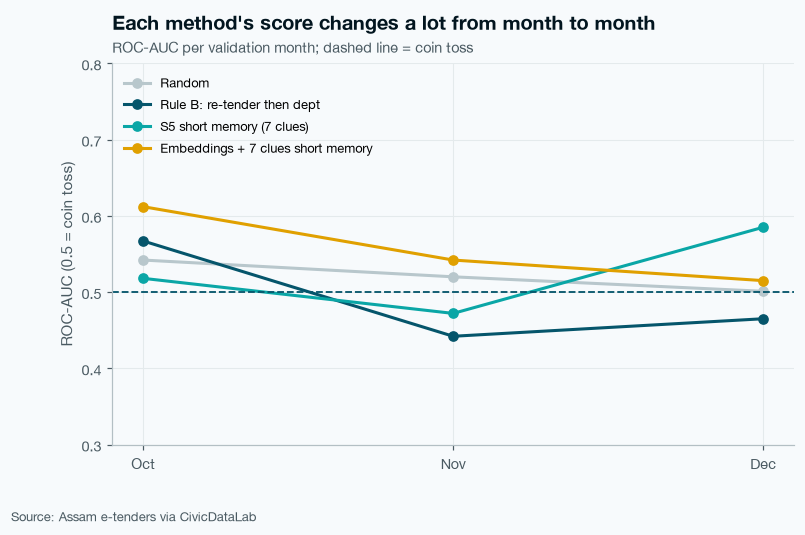

In [144]:
# Chart S6j: ROC-AUC per month for each method
fig, ax = plt.subplots(figsize=(8, 4.5))
line_colors = [ts.NEUTRAL, ts.THIRD, ts.BLUES[3], ts.SINGLE]
for k, name in enumerate(compare):
    ax.plot(["Oct", "Nov", "Dec"], month_table.loc[name], marker="o", color=line_colors[k], label=name)

# Coin-toss line at 0.5, room, axis name, legend
ax.axhline(0.5, color=ts.THIRD, linestyle="--", linewidth=1.2)
ax.set_ylim(0.3, 0.8)
ax.set_ylabel("ROC-AUC (0.5 = coin toss)")
ax.legend(loc="upper left", fontsize=8.5)

# Title, subtitle, source
ts.title(ax, "Each method's score changes a lot from month to month",
         subtitle="ROC-AUC per validation month; dashed line = coin toss")
ts.source(fig)

In [145]:
ts.save_fig(fig, "../reports/figures/S6j_month_by_month.png")

### Insight · Embeddings, text clues and monthly retraining (Steps 13 to 16)

- Embeddings are a smarter way to turn text into numbers. They look at the meaning, so "road" and "highway" come out close to each other.
- The embeddings model learned from train got PR-AUC 0.300 and caught 22.7% in the top 20%. This is a little better than random (0.288 and 19.8%).
- Adding the number clues or the 3 new text clues did not help.
- Then I tried the text inside the S5 drift fixes (learning again every month). These looked better. The best was embeddings + 7 clues with short memory: PR-AUC 0.332 and 26.5% caught.
- Month by month, this model was good in October (0.612) but only a little better than a coin toss by December (0.515).
- It looked like the best result so far, but I checked it carefully before trusting it (Step 17).

## Step 17 · Fair checks before we call anything a win

### 17a · Repeated lots counted once

In [146]:
# True for the first tender of each department + cleaned title in validation, False for copies
first_only = ~val.duplicated(["dept_main", "title_key"]).values
print("Validation tenders:", len(val), "| counting repeats once:", first_only.sum())

Validation tenders: 2270 | counting repeats once: 2157


In [147]:
# PR-AUC with all tenders vs with repeats counted once
for name in compare:
    r = risks[name]
    print(name, "| all:", round(average_precision_score(y_va, r), 3),
          "| repeats once:", round(average_precision_score(y_va[first_only], r[first_only]), 3))

Random | all: 0.288 | repeats once: 0.283
Rule B: re-tender then dept | all: 0.268 | repeats once: 0.261
S5 short memory (7 clues) | all: 0.313 | repeats once: 0.312
Embeddings + 7 clues short memory | all: 0.332 | repeats once: 0.331


### 17b · Timing check: were the answers really known when we learned from them?

A tender's answer (one bid or more) is only known on its bid opening day, usually about 19 days after it is published.
In monthly retraining, before November we learned from ALL tenders published before November. But a tender published on 25 October opens its bids in mid-November, so on 1 November nobody knew its answer yet.
A real auditor could only learn from tenders whose bids were ALREADY opened. So we run every monthly plan again with `opened_only=True`.

In [148]:
# How many learning tenders were NOT opened yet at the start of each month?
for start in ["2022-10-01", "2022-11-01", "2022-12-01"]:
    earlier = tv[tv["published_date"] < start]
    not_opened = (earlier["bid_opening_date"] >= start).sum()
    print("Start", start, "| earlier tenders:", len(earlier), "| bids not opened yet:", not_opened)

Start 2022-10-01 | earlier tenders: 2812 | bids not opened yet: 254
Start 2022-11-01 | earlier tenders: 3070 | bids not opened yet: 202
Start 2022-12-01 | earlier tenders: 3802 | bids not opened yet: 434


In [149]:
# Validation tenders whose bids opened in a LATER month than they were published
later = val["bid_opening_date"].dt.to_period("M") > val["published_date"].dt.to_period("M")
print("Opened in a later month:", later.sum(), "of", len(val))

Opened in a later month: 1098 of 2270


In [150]:
# Run every monthly plan again, learning only from tenders whose bids were already opened
for p in plans:
    name = p["name"] + " (opened only)"
    risks[name] = monthly_risk(p["kind"], p["clues"], p["memory"], opened_only=True)
    results.append(score_row(name, y_va, risks[name]))

In [151]:
# Side by side: PR-AUC as in S5 vs opened only
rows = []
for p in plans:
    old = average_precision_score(y_va, risks[p["name"]])                      # as in S5
    fair = average_precision_score(y_va, risks[p["name"] + " (opened only)"])  # opened only
    rows.append({"model": p["name"], "PR-AUC as in S5": old, "PR-AUC opened only": fair})
timing = pd.DataFrame(rows)
timing["change"] = timing["PR-AUC opened only"] - timing["PR-AUC as in S5"]
timing.round(3)

,model,PR-AUC as in S5,PR-AUC opened only,change
0,S5 monthly retrain (7 clues),0.258,0.248,-0.010
1,S5 short memory (7 clues),0.313,0.243,-0.069
2,TF-IDF monthly,0.327,0.265,-0.062
3,TF-IDF short memory,0.319,0.239,-0.080
4,TF-IDF + 7 clues monthly,0.330,0.260,-0.069
5,TF-IDF + 7 clues short memory,0.313,0.232,-0.081
6,Embeddings monthly,0.330,0.277,-0.053
7,Embeddings short memory,0.325,0.258,-0.067
8,Embeddings + 7 clues monthly,0.329,0.271,-0.058
9,Embeddings + 7 clues short memory,0.332,0.255,-0.077


In [152]:
# Fair text methods = text models learned once from train (Steps 11-14) + monthly text plans with opened only
fair_names = ["TF-IDF alone", "TF-IDF + 7 clues", "TF-IDF + 34 clues", "Embeddings alone",
              "Embeddings + 7 clues", "Embeddings + 34 clues", "7 clues + 3 text clues", "34 clues + 3 text clues"]
for p in plans:
    if not p["name"].startswith("S5"):
        fair_names.append(p["name"] + " (opened only)")

In [153]:
# Best fair text method (highest PR-AUC on validation)
fair_table = pd.DataFrame(results)
fair_table = fair_table[fair_table["model"].isin(fair_names)].sort_values("PR-AUC", ascending=False)
best_fair = fair_table.iloc[0]["model"]
fair_table.head(5)

,model,PR-AUC,ROC-AUC,capture top 10%,capture top 20%
6,Embeddings alone,0.300,0.507,13.2,22.7
7,Embeddings + 7 clues,0.297,0.502,13.3,21.9
8,Embeddings + 34 clues,0.292,0.509,11.4,22.7
9,7 clues + 3 text clues,0.284,0.469,12.2,19.8
27,Embeddings monthly (opened only),0.277,0.482,10.8,20.2


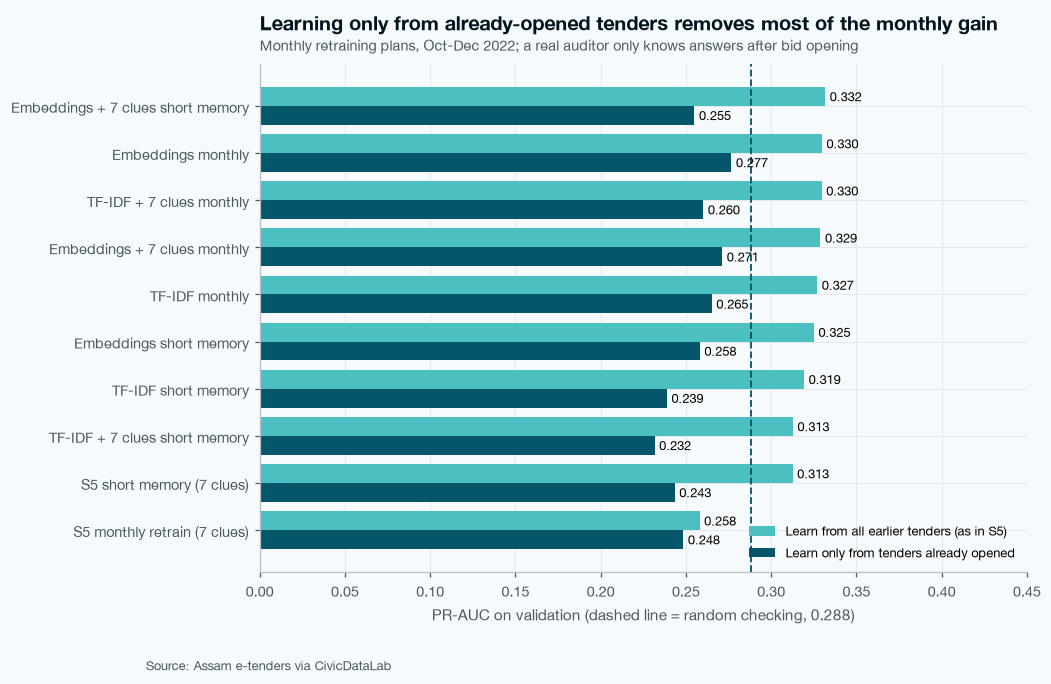

In [154]:
# Chart S6k: PR-AUC as in S5 vs opened only, for every monthly plan
show = timing.sort_values("PR-AUC as in S5")
pos = np.arange(len(show))
fig, ax = plt.subplots(figsize=(9, 6))
b1 = ax.barh(pos + 0.2, show["PR-AUC as in S5"], height=0.4, color=ts.BLUES[2], label="Learn from all earlier tenders (as in S5)")
b2 = ax.barh(pos - 0.2, show["PR-AUC opened only"], height=0.4, color=ts.BLUES[4], label="Learn only from tenders already opened")

# Value labels, dashed line = Random, names, room, legend
ax.bar_label(b1, fmt="%.3f", padding=3, fontsize=8.5)
ax.bar_label(b2, fmt="%.3f", padding=3, fontsize=8.5)
ax.axvline(0.288, color=ts.THIRD, linestyle="--", linewidth=1.2)
ax.set_yticks(pos, show["model"])
ax.set_xlim(0, 0.45)
ax.set_xlabel("PR-AUC on validation (dashed line = random checking, 0.288)")
ax.legend(loc="lower right", fontsize=8.5)

# Title, subtitle, source
ts.title(ax, "Learning only from already-opened tenders removes most of the monthly gain",
         subtitle="Monthly retraining plans, Oct-Dec 2022; a real auditor only knows answers after bid opening")
ts.source(fig)

In [155]:
ts.save_fig(fig, "../reports/figures/S6k_timing_check.png")

### 17c · Lucky or real? 500 re-draws (bootstrap)

In [156]:
# Answers as a plain array
y_arr = y_va.values

In [157]:
# Helper 6: in 500 re-draws, how often does method A beat method B on PR-AUC?
def bootstrap(a, b):
    rng = np.random.default_rng(42)                                 # fixed seed (same draws every run)
    gaps = []
    for i in range(500):
        pick = rng.integers(0, len(val), len(val))                  # pick tenders with replacement
        gap = average_precision_score(y_arr[pick], risks[a][pick]) - average_precision_score(y_arr[pick], risks[b][pick])
        gaps.append(gap)
    return np.array(gaps)

In [158]:
# Best text (as in S5 timing) vs Random
gaps_text = bootstrap(best_text, "Random")
print(best_text, "beats Random in", round((gaps_text > 0).mean() * 100, 1), "% of draws |",
      "middle 95% of the gap:", np.percentile(gaps_text, [2.5, 97.5]).round(3))

Embeddings + 7 clues short memory beats Random in 99.8 % of draws | middle 95% of the gap: [0.012 0.079]


In [159]:
# Best text (as in S5 timing) vs S5 short memory
gaps_vs_s5 = bootstrap(best_text, "S5 short memory (7 clues)")
print(best_text, "beats S5 short memory in", round((gaps_vs_s5 > 0).mean() * 100, 1), "% of draws |",
      "middle 95%:", np.percentile(gaps_vs_s5, [2.5, 97.5]).round(3))

Embeddings + 7 clues short memory beats S5 short memory in 88.2 % of draws | middle 95%: [-0.014  0.052]


In [160]:
# Best fair text method vs Random
gaps_fair = bootstrap(best_fair, "Random")
print(best_fair, "beats Random in", round((gaps_fair > 0).mean() * 100, 1), "% of draws |",
      "middle 95%:", np.percentile(gaps_fair, [2.5, 97.5]).round(3))

Embeddings alone beats Random in 75.0 % of draws | middle 95%: [-0.02   0.041]


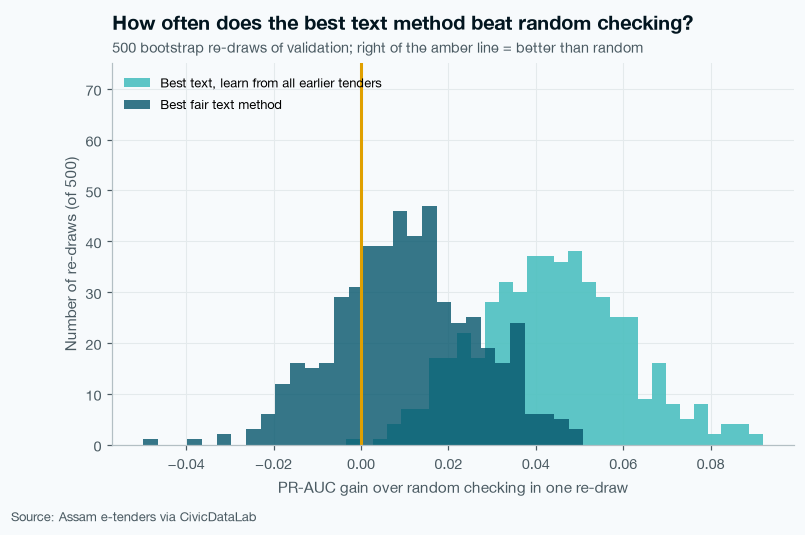

In [161]:
# Chart S6l: the 500 gaps vs Random, as in S5 timing and with fair timing
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist(gaps_text, bins=30, color=ts.BLUES[2], alpha=0.9, label="Best text, learn from all earlier tenders")
ax.hist(gaps_fair, bins=30, color=ts.BLUES[4], alpha=0.8, label="Best fair text method")

# Line at 0 = no gain over random checking
ax.axvline(0, color=ts.SINGLE, linewidth=2)

# Axis names and legend
ax.set_xlabel("PR-AUC gain over random checking in one re-draw")
ax.set_ylabel("Number of re-draws (of 500)")
ax.set_ylim(0, 75)
ax.legend(loc="upper left", fontsize=8.5)

# Title, subtitle, source
ts.title(ax, "How often does the best text method beat random checking?",
         subtitle="500 bootstrap re-draws of validation; right of the amber line = better than random")
ts.source(fig)

In [162]:
ts.save_fig(fig, "../reports/figures/S6l_bootstrap.png")

## Step 18 · Do embeddings add anything beyond the 8 simple keyword flags?

In [163]:
# The 8 keyword flags from S5
kw_cols = ["kw_maintenance", "kw_printing", "kw_supply", "kw_building",
           "kw_construction", "kw_road", "kw_repair", "kw_renovation"]

In [164]:
# Keyword flags alone, embeddings alone, and both together (all learned once from train)
risks["8 keyword flags"] = lr_risk(train, y_tr, val, kw_cols)
risks["Embeddings + 8 keyword flags"] = lr_risk(train, y_tr, val, kw_cols + emb_cols)
results.append(score_row("8 keyword flags", y_va, risks["8 keyword flags"]))
results.append(score_row("Embeddings + 8 keyword flags", y_va, risks["Embeddings + 8 keyword flags"]))

In [165]:
# Side by side
pick = ["8 keyword flags", "TF-IDF alone", "Embeddings alone", "Embeddings + 8 keyword flags"]
all_rows = pd.DataFrame(results)
all_rows[all_rows["model"].isin(pick)]

,model,PR-AUC,ROC-AUC,capture top 10%,capture top 20%
3,TF-IDF alone,0.274,0.474,9.2,19.8
6,Embeddings alone,0.300,0.507,13.2,22.7
31,8 keyword flags,0.233,0.403,5.4,8.9
32,Embeddings + 8 keyword flags,0.291,0.498,12.4,21.4


### Insight · Fair checks (Steps 17 and 18)

- Counting repeated pieces of the same work only once did not change anything (0.332 to 0.331).
- Timing check, the most important one: we only know if a tender got one bid after its bids are opened, about 19 days after it is published.
- When the model learned again each month, it also learned from tenders whose bids were not opened yet. For example, before 1 December it used 434 tenders whose answers nobody knew yet. In real life an auditor could not do that.
- So I ran everything again, learning only from tenders whose bids were already opened.
- All the monthly gains went away. S5 short memory went from 0.313 to 0.243. The best text model went from 0.332 to 0.255. Both are now below random (0.288).
- So the good results from monthly learning were partly using answers from the future. They are not real wins.
- The best fair text model is embeddings learned once from train (0.300). In the 500 re-draws it beat random only 75% of the time, so I cannot say it is really better than random.
- Embeddings did a little better than the 8 simple word flags from S5 (0.300 vs 0.233), but not enough to call it a win.
- Small note: models learned once from train also used about 254 September tenders whose bids opened in October. This is very small, and the S5 models had the same thing.

# Part D · Results, auditor view, saves and extra checks

## Step 19 · Full results table

In [166]:
# Every method in one table, best PR-AUC first
table = pd.DataFrame(results).sort_values("PR-AUC", ascending=False)
table

,model,PR-AUC,ROC-AUC,capture top 10%,capture top 20%
20,Embeddings + 7 clues short memory,0.332,0.556,13.7,26.5
17,Embeddings monthly,0.330,0.554,14.9,25.4
15,TF-IDF + 7 clues monthly,0.330,0.580,10.6,25.6
19,Embeddings + 7 clues monthly,0.329,0.549,15.9,24.8
13,TF-IDF monthly,0.327,0.586,10.3,25.1
18,Embeddings short memory,0.325,0.564,14.3,24.9
14,TF-IDF short memory,0.319,0.588,9.5,20.3
16,TF-IDF + 7 clues short memory,0.313,0.590,8.7,22.9
12,S5 short memory (7 clues),0.313,0.540,11.9,25.4
6,Embeddings alone,0.300,0.507,13.2,22.7


In [167]:
# The key methods for the chart (benchmarks, S5 best, text methods, and the fair-timing versions)
key = ["Random", "Rule B: re-tender then dept", "S5 LogReg (34 clues)",
       "S5 monthly retrain (7 clues)", "S5 short memory (7 clues)", "S5 short memory (7 clues) (opened only)",
       "TF-IDF alone", "TF-IDF + 34 clues", "Embeddings alone", "Embeddings + 34 clues",
       "34 clues + 3 text clues", best_text, best_fair]

In [168]:
# Keep only the key rows (each name once), lowest PR-AUC at the bottom of the chart
key_table = table[table["model"].isin(key)].sort_values("PR-AUC")
benchmarks = ["Random", "Rule B: re-tender then dept"]
key_table

,model,PR-AUC,ROC-AUC,capture top 10%,capture top 20%
22,S5 short memory (7 clues) (opened only),0.243,0.407,10.3,16.5
2,S5 LogReg (34 clues),0.245,0.417,7.3,15.2
10,34 clues + 3 text clues,0.257,0.440,8.3,19.5
11,S5 monthly retrain (7 clues),0.258,0.430,12.2,17.8
5,TF-IDF + 34 clues,0.264,0.460,7.9,15.7
1,Rule B: re-tender then dept,0.268,0.431,12.5,14.6
3,TF-IDF alone,0.274,0.474,9.2,19.8
0,Random,0.288,0.514,11.1,19.8
8,Embeddings + 34 clues,0.292,0.509,11.4,22.7
6,Embeddings alone,0.300,0.507,13.2,22.7


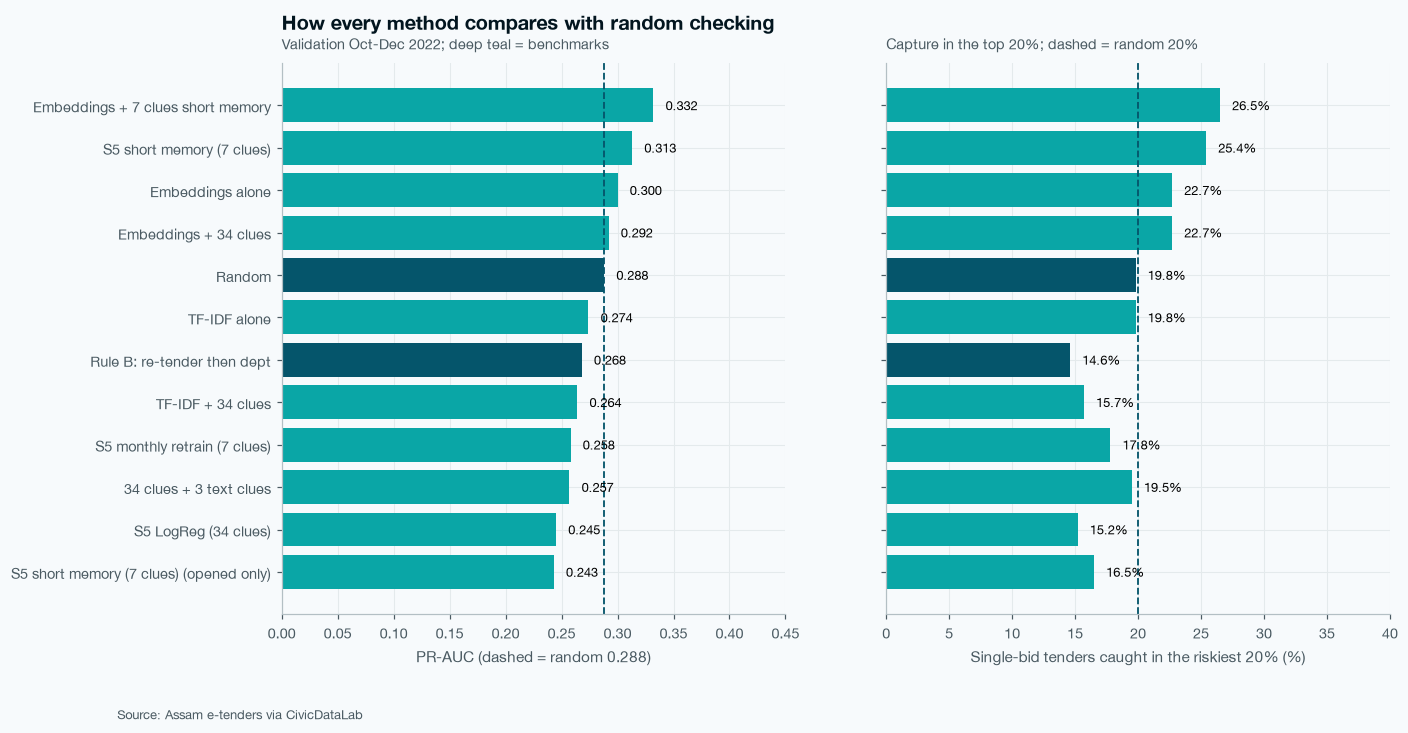

In [169]:
# Chart S6m: PR-AUC (left) and capture top 20% (right) for the key methods
colors = np.where(key_table["model"].isin(benchmarks), ts.THIRD, ts.MULTI)
fig, axes = plt.subplots(1, 2, figsize=(13, 6.5), sharey=True)

# Left: PR-AUC with the random line
b1 = axes[0].barh(key_table["model"], key_table["PR-AUC"], color=colors)
axes[0].bar_label(b1, fmt="%.3f", padding=8, fontsize=8.5)
axes[0].axvline(0.288, color=ts.THIRD, linestyle="--", linewidth=1.2)
axes[0].set_xlim(0, 0.45)
axes[0].set_xlabel("PR-AUC (dashed = random 0.288)")
ts.title(axes[0], "How every method compares with random checking", subtitle="Validation Oct-Dec 2022; deep teal = benchmarks")

# Right: capture in the riskiest 20% with the random 20% line
b2 = axes[1].barh(key_table["model"], key_table["capture top 20%"], color=colors)
axes[1].bar_label(b2, fmt="%.1f%%", padding=8, fontsize=8.5)
axes[1].axvline(20, color=ts.THIRD, linestyle="--", linewidth=1.2)
axes[1].set_xlim(0, 40)
axes[1].set_xlabel("Single-bid tenders caught in the riskiest 20% (%)")
ts.title(axes[1], " ", subtitle="Capture in the top 20%; dashed = random 20%")

# Source line
ts.source(fig)

In [170]:
ts.save_fig(fig, "../reports/figures/S6m_results.png")

## Step 20 · Auditor view: check the riskiest 20%

In [171]:
# How many tenders the auditor checks (20% of validation), and all single-bid tenders
n_check = int(len(val) * 0.2)
print("Checked:", n_check, "| all single-bid tenders in validation:", int(y_va.sum()))

Checked: 454 | all single-bid tenders in validation: 630


In [172]:
# Helper 7: the riskiest 20% of validation tenders for any risk score
def top20(risk):
    t = val[["single_bid", "estimated_value"]].copy()               # answer and rupee value
    t["risk"] = risk                                                # add the risk score
    t = t.sort_values("risk", ascending=False, kind="stable")       # riskiest first
    return t.head(n_check)                                          # keep the top 20%

In [173]:
# Methods for the auditor view
auditor_names = ["Random", "Rule B: re-tender then dept", "S5 short memory (7 clues)",
                 best_text, "S5 short memory (7 clues) (opened only)", best_fair]

In [174]:
# Single-bid tenders caught and their value in crore (1 crore = 1,00,00,000)
rows = []
for name in auditor_names:
    top = top20(risks[name])
    caught = int(top["single_bid"].sum())
    crore = top.loc[top["single_bid"] == 1, "estimated_value"].sum() / 1e7
    rows.append({"method": name, "caught": caught, "Rs crore": round(crore, 1)})
auditor = pd.DataFrame(rows)
auditor

,method,caught,Rs crore
0,Random,125,233.1
1,Rule B: re-tender then dept,92,425.9
2,S5 short memory (7 clues),160,455.0
3,Embeddings + 7 clues short memory,167,317.7
4,S5 short memory (7 clues) (opened only),104,358.2
5,Embeddings alone,143,253.2


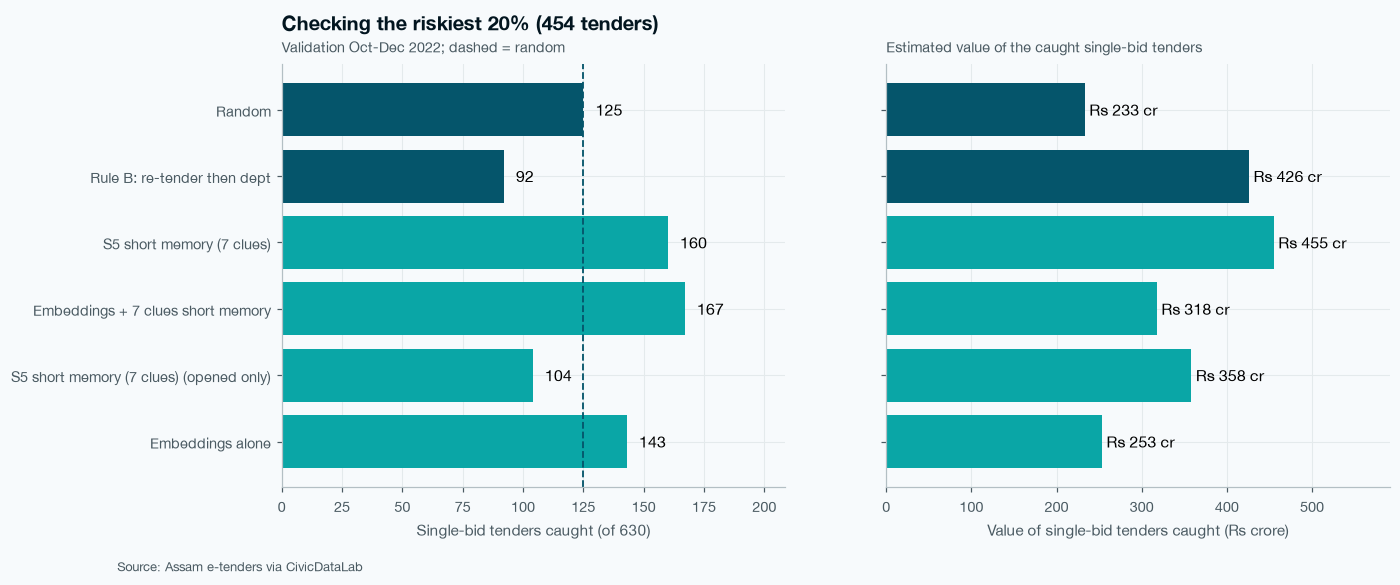

In [175]:
# Chart S6n: caught (left) and rupee value covered (right) for each method
colors = np.where(auditor["method"].isin(benchmarks), ts.THIRD, ts.MULTI)
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)

# Left: single-bid tenders caught, with the random number as a dashed line
b1 = axes[0].barh(auditor["method"], auditor["caught"], color=colors)
axes[0].bar_label(b1, padding=8)
axes[0].axvline(auditor.loc[0, "caught"], color=ts.THIRD, linestyle="--", linewidth=1.2)
axes[0].set_xlim(0, auditor["caught"].max() * 1.25)
axes[0].invert_yaxis()
axes[0].set_xlabel("Single-bid tenders caught (of " + str(int(y_va.sum())) + ")")
ts.title(axes[0], "Checking the riskiest 20% (" + str(n_check) + " tenders)", subtitle="Validation Oct-Dec 2022; dashed = random")

# Right: rupee value of the single-bid tenders caught
b2 = axes[1].barh(auditor["method"], auditor["Rs crore"], color=colors)
axes[1].bar_label(b2, fmt="Rs %.0f cr", padding=3)
axes[1].set_xlim(0, auditor["Rs crore"].max() * 1.3)
axes[1].set_xlabel("Value of single-bid tenders caught (Rs crore)")
ts.title(axes[1], " ", subtitle="Estimated value of the caught single-bid tenders")

# Source line
ts.source(fig)

In [176]:
ts.save_fig(fig, "../reports/figures/S6n_auditor_view.png")

### Insight · Results and auditor view (Steps 19 and 20)

- The two top methods in the table (0.332 and 0.313) are the ones that failed the timing check, so I do not count them.
- Of the fair methods, only embeddings (0.300 and 0.292) are a little above random (0.288).
- If an auditor checks the riskiest 20% of validation tenders (454 tenders), there are 630 single-bid tenders in total to find.
- Random checking finds 125 of them, worth Rs 233.1 crore.
- Rule B finds 92, worth Rs 425.9 crore.
- Embeddings find 143, worth Rs 253.2 crore. That is 18 more than random, the best fair result.
- Rule B and the S5 models find fewer single-bid tenders but bigger ones (more rupees). I need to check this again on test.

## Step 21 · Save everything

In [177]:
# 1. New text clues for ALL labelled tenders (made without answers, or from training answers only)
text_out = lab[["tender_id", "split", "near_sim", "near_retender", "similar_rate", "tight_word", "work_type"]]
text_out.to_csv("../data/processed/s6_text_clues.csv", index=False)
text_out.shape

(6790, 7)

In [178]:
# 2. Results table
table.to_csv("../reports/s6_nlp_results.csv", index=False)

In [179]:
# 3. Validation tenders with the risk scores of the main methods
val_out = val[["tender_id", "published_date", "dept_main", "work_type", "title", "estimated_value", "single_bid"]].copy()
for name in auditor_names:
    val_out["risk: " + name] = risks[name]
val_out.to_csv("../reports/s6_val_predictions.csv", index=False)
val_out.shape

(2270, 13)

In [180]:
# 4. Small tables behind the charts (handy for the report)
word_table.to_csv("../reports/s6_word_flip.csv", index=False)
mix.round(1).to_csv("../reports/s6_work_type_mix.csv")
type_rate.round(1).to_csv("../reports/s6_work_type_rate.csv")
timing.round(3).to_csv("../reports/s6_timing_check.csv", index=False)
print("All saved")

All saved


## Step 22 · Did we miss anything? (extra checks)

After the main steps I went back to my checklist and looked for anything still missing:
- 22a: title only vs title + description
- 22b: letter pieces instead of whole words (catches short forms like "Constn" for "Construction")
- 22c: does text work INSIDE the training period? (like S5 Step 13)
- 22d: work type as a clue in the model
- 22e: is 0.8 a lucky choice for near re-tenders? (try 0.7 and 0.9)
- 22f: top 50 / 100 / 200 for the auditor

### 22a · Title only vs title + description

In [181]:
# Use the title as the text (copy so we do not change train and val)
train_title = train.copy()
val_title = val.copy()
train_title["text"] = train_title["title"]
val_title["text"] = val_title["title"]

In [182]:
# TF-IDF on titles only vs title + description
rows = []
rows.append(score_row("TF-IDF title only", y_va, tfidf_risk(train_title, y_tr, val_title)))
rows.append(score_row("TF-IDF title + description", y_va, risks["TF-IDF alone"]))
pd.DataFrame(rows)

,model,PR-AUC,ROC-AUC,capture top 10%,capture top 20%
0,TF-IDF title only,0.293,0.502,10.3,20.5
1,TF-IDF title + description,0.274,0.474,9.2,19.8


### 22b · Letter pieces instead of whole words

In [183]:
# analyzer="char_wb" = pieces of 3 to 5 letters inside words, so "constn" and "construction" share "con", "cons", "onst" ...
char_vec = TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), min_df=5)
C_tr = char_vec.fit_transform(train["text"])
C_va = char_vec.transform(val["text"])

In [184]:
# Same model as before, on letter pieces
char_lr = LogisticRegression(class_weight="balanced", max_iter=3000)
char_lr.fit(C_tr, y_tr)
pd.DataFrame([score_row("TF-IDF letter pieces", y_va, char_lr.predict_proba(C_va)[:, 1])])

,model,PR-AUC,ROC-AUC,capture top 10%,capture top 20%
0,TF-IDF letter pieces,0.251,0.437,7.9,14.3


### 22c · Does text work inside the training period?

In [185]:
# Check 1: learn from tenders before Apr 2022, score Apr-Jun 2022
learn = train[train["published_date"] < "2022-04-01"]
check = train[(train["published_date"] >= "2022-04-01") & (train["published_date"] < "2022-07-01")]
print("Learned from", len(learn), "| scored", len(check))
print("  7 clues ROC:", round(roc_auc_score(check["single_bid"], lr_risk(learn, learn["single_bid"], check, base)), 3))
print("  TF-IDF  ROC:", round(roc_auc_score(check["single_bid"], tfidf_risk(learn, learn["single_bid"], check)), 3))
print("  Embeddings ROC:", round(roc_auc_score(check["single_bid"], lr_risk(learn, learn["single_bid"], check, emb_cols)), 3))

Learned from 727 | scored 1042
  7 clues ROC: 0.531
  TF-IDF  ROC: 0.482
  Embeddings ROC: 0.488


In [186]:
# Check 2: learn from tenders before Jul 2022, score Jul-Sep 2022
learn = train[train["published_date"] < "2022-07-01"]
check = train[train["published_date"] >= "2022-07-01"]
print("Learned from", len(learn), "| scored", len(check))
print("  7 clues ROC:", round(roc_auc_score(check["single_bid"], lr_risk(learn, learn["single_bid"], check, base)), 3))
print("  TF-IDF  ROC:", round(roc_auc_score(check["single_bid"], tfidf_risk(learn, learn["single_bid"], check)), 3))
print("  Embeddings ROC:", round(roc_auc_score(check["single_bid"], lr_risk(learn, learn["single_bid"], check, emb_cols)), 3))

Learned from 1769 | scored 984
  7 clues ROC: 0.577
  TF-IDF  ROC: 0.585
  Embeddings ROC: 0.511


### 22d · Work type as a clue

In [187]:
# Work type as 0/1 columns (one per type)
wt = pd.get_dummies(tv["work_type"], prefix="wt", dtype=int)
wt_cols = list(wt.columns)

In [188]:
# Add them to train and validation (copies, so the main tables stay the same)
train_wt = pd.concat([train, wt.loc[train.index]], axis=1)
val_wt = pd.concat([val, wt.loc[val.index]], axis=1)
pd.DataFrame([score_row("7 clues + work type", y_va, lr_risk(train_wt, y_tr, val_wt, base + wt_cols))])

,model,PR-AUC,ROC-AUC,capture top 10%,capture top 20%
0,7 clues + work type,0.28,0.451,13.5,21.6


### 22e · Near re-tender with other cut-offs

In [189]:
# Single-bid rate (%) of near re-tenders with cut-off 0.7, 0.8 and 0.9
for cut_off in [0.7, 0.8, 0.9]:
    near = (tv["near_sim"] >= cut_off) & (tv["retender_60d"] == 0)
    print("Cut-off", cut_off,
          "| train:", near[tv["split"] == "train"].sum(), "tenders,", round(tv.loc[near & (tv["split"] == "train"), "single_bid"].mean() * 100, 1),
          "% | val:", near[tv["split"] == "val"].sum(), "tenders,", round(tv.loc[near & (tv["split"] == "val"), "single_bid"].mean() * 100, 1), "%")

Cut-off 0.7 | train: 451 tenders, 34.8 % | val: 804 tenders, 19.9 %
Cut-off 0.8 | train: 338 tenders, 32.8 % | val: 639 tenders, 20.3 %
Cut-off 0.9 | train: 176 tenders, 33.5 % | val: 502 tenders, 23.5 %


### 22f · Top 50 / 100 / 200 for the auditor

In [190]:
# Share (%) of single-bid tenders among the top K (validation average = 27.8%)
for name in ["Random", "S5 short memory (7 clues)", best_text, best_fair]:
    t = pd.DataFrame({"real": y_va.values, "risk": risks[name]}).sort_values("risk", ascending=False, kind="stable")
    print(name, "| top 50:", round(t.head(50)["real"].mean() * 100, 1),
          "% | top 100:", round(t.head(100)["real"].mean() * 100, 1),
          "% | top 200:", round(t.head(200)["real"].mean() * 100, 1), "%")

Random | top 50: 38.0 % | top 100: 32.0 % | top 200: 30.5 %
S5 short memory (7 clues) | top 50: 30.0 % | top 100: 28.0 % | top 200: 34.5 %
Embeddings + 7 clues short memory | top 50: 40.0 % | top 100: 42.0 % | top 200: 39.0 %
Embeddings alone | top 50: 36.0 % | top 100: 36.0 % | top 200: 38.0 %


### Insight · Extra checks (Step 22)

- Using only the title (0.293) worked as well as title + description (0.274). The description adds almost nothing.
- Using small pieces of words to catch short forms like "Constn" made it worse (0.251).
- Even inside the training period, before the drift, the words were not better than the number clues. For example, scoring Apr-Jun 2022, the clues got 0.531, TF-IDF 0.482 and embeddings 0.488 (0.5 = coin toss).
- Adding work type as a clue helped a little (0.280) but was still below random.
- Similar-title tenders had a low single-bid rate in validation whether I used 0.7, 0.8 or 0.9 as the cut-off. So that finding is steady.

## S6 Summary - NLP

### Starting point
- I started with 6,790 labelled tenders and 34 clues from S5.
- In S5 no model beat random checking on validation, because the pattern changed after Sep 2022. Short memory (0.313) was the only one above random.
- In S6 I wanted to know two things. Do the words of a tender help find single-bid tenders? And do the words explain why the pattern changed?

### What I did
- Joined title and description into one text, and checked text length and empty descriptions.
- Found copies of the same work, and checked if words change meaning over time.
- Made 3 new text clues: brand and dealer words, similar-title re-tenders, and the single-bid rate of similar older tenders.
- Gave every tender a simple work type and compared train, Oct-Nov and December.
- Tested if words alone can tell old tenders from new ones.
- Tried two ways of turning text into numbers (TF-IDF and embeddings), alone, with clues, and with monthly learning.
- Did fair checks: repeats counted once, a timing check, and 500 re-draws.
- Did 5 extra checks at the end.

### What I found
- Most descriptions just copy the title, and the portal cuts text at 250 letters. So the text is short and simple.
- 46 of 69 common words changed direction after Sep 2022.
- Exact copies and exact re-tenders often got one bid again (43.3% and 58.3%). Similar-looking titles did not (20.3%).
- Brand and dealer words were almost never used, so I could not test them.
- December 2022 was almost half road work, and road tenders got far fewer single bids (14.5%).
- Words alone can tell old tenders from new ones very easily (0.913), because new government schemes came in. This is the reason for the drift.
- TF-IDF was no better than random. Embeddings were a little better (catching 143 vs 125), but not proven.
- The biggest finding: learning again every month used answers that were not known yet. With the fair timing rule, all monthly gains went away, including S5 short memory.

### Candidates for S7 (decided before looking at test)
- Random checking (benchmark).
- Rule B: re-tender first, then department (benchmark).
- Logistic Regression with 7 clues, learning again every month, but only from tenders whose bids were already opened.
- Embeddings learned once from train (best fair text model, not proven yet).
- Dropped: S5 short memory and all monthly text models that used answers not known yet.

### Files saved
- data/processed/s6_text_clues.csv (new text clues and work type for all 6,790 tenders)
- data/processed/s6_embeddings_train_val.npy (the embedding numbers, so they do not need to be made again)
- reports/s6_nlp_results.csv, s6_val_predictions.csv, s6_word_flip.csv, s6_work_type_mix.csv, s6_work_type_rate.csv, s6_timing_check.csv
- reports/figures S6a to S6n (14 charts)

### Next steps
- S7: test the candidates once on the test set (Jan-May 2023), using the fair timing rule.
- Check again on test if the models find bigger single-bid tenders (more rupees).
- Use SHAP to explain why a tender gets a high risk.
- Slides from S6: S6g (December was mostly road work, and road tenders lost single bids), S6h (words alone tell old from new) and S6k (fair timing removes the monthly gains).